# Zomato Restaurant Clustering and Customer Sentiment Analysis

##### **Project Type** - Unsupervised Machine Learning (with exploratory data analysis and sentiment analysis)

##### **Contribution** - Individual

##### **Team Member 1** - Hasini Bavirisetty

##### **Team Member 2–4** - Not applicable

# **Project Summary -**

## Project Summary

This project analyses Zomato restaurant metadata and customer reviews to understand restaurant characteristics, customer feedback and similarities between restaurants. The work combines exploratory data analysis, review sentiment analysis and unsupervised machine learning. The business objective is to turn restaurant and review data into interpretable information that may help customers compare restaurants and help businesses understand restaurant segments and customer experience.

Two datasets were used: restaurant metadata and customer reviews. The metadata includes restaurant names, links, approximate dining cost, collections and cuisines. The review dataset includes restaurant/reviewer information, review text, ratings and reviewer metadata. The datasets were cleaned and restaurant-level information was created by aggregating review ratings. Restaurant names were normalised for matching before the metadata and rating summaries were merged. The clustering analysis used three numerical features: Cost, Average_Rating and Total_Reviews. Missing or infinite values in the selected clustering features were excluded from the clustering input.

Exploratory charts examined ratings, cuisines, costs, restaurant averages, cluster patterns and review sentiment. VADER was applied to review text to classify reviews as positive, neutral or negative. In the analysed review set of 9,955 records, 7,392 (74.25%) were positive, 717 (7.20%) neutral and 1,846 (18.54%) negative. Common positive words included “good”, “food”, “place” and “service”; negative reviews included terms such as “bad”, “worst”, “experience” and “service”. These results provide a high-level view of customer opinion, but automated sentiment can miss sarcasm, context and multilingual expressions.

Three clustering algorithms were implemented: K-Means, Agglomerative Clustering and DBSCAN. The features were standardised using StandardScaler because cost, rating and review count have different scales. With the corrected three-feature workflow, K-Means tuning selected K=3 with a silhouette score of 0.4673 and final group sizes of 24, 74 and 2. Agglomerative Clustering at K=3 scored 0.4181. DBSCAN scored 0.5098 on its 56 non-noise restaurants and labeled 44 restaurants as noise, so that score is not directly comparable with models evaluated on all 100 restaurants.

Hypothesis tests examined differences in ratings across cost groups, the association between cost and average rating, and the association between numerical ratings and text-derived sentiment. The results indicated statistically significant relationships in this dataset; statistical significance does not establish causation. Limitations include the relatively small merged restaurant sample (100 restaurants), the near-constant review-count feature for many restaurants, and the limitations of rule-based sentiment analysis. Further work could add more locations, restaurants, cuisine and geographic features, test more robust text models, profile clusters in greater detail and deploy a reproducible prediction workflow.

# **GitHub Link -**

https://github.com/hasinibavirisetty15-cpu/Zomato-Restaurant-Clustering-Labmentix

# **Problem Statement**


The project addresses the need to understand restaurant characteristics and customer opinions from Zomato data. The work combines restaurant metadata with customer reviews, explores ratings, cuisines and costs, analyses review sentiment, and groups restaurants with similar numerical characteristics using unsupervised clustering. The goal is to produce interpretable business insights that can support restaurant comparison and help businesses understand customer experience and restaurant segments. The analysis is exploratory and does not claim to predict restaurant success or prove that one factor causes another.

# ***Let's Begin !***

## 1. Know Your Data and Prepare the Datasets

The following executable sections load the two supplied CSV files, inspect them, clean their fields, and build the restaurant-level dataset used throughout the analysis. The loader checks the notebook folder and a sibling `outputs` folder, so the notebook works both from the delivered bundle and from the project root.


In [1]:
# Step 1: Import required libraries

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

# Locate the supplied CSV files beside this notebook or in the project outputs folder.
base_dir = Path.cwd()
search_dirs = [base_dir, base_dir / "outputs", base_dir.parent / "outputs"]
def find_dataset(filename):
    for folder in search_dirs:
        candidate = folder / filename
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"Could not find {filename}. Place both CSV files beside the notebook or in an outputs folder.")

reviews_path = find_dataset("Zomato Restaurant reviews.csv")
restaurants_path = find_dataset("Zomato Restaurant names and Metadata.csv")
reviews = pd.read_csv(reviews_path)
restaurants = pd.read_csv(restaurants_path)
print(f"Loaded reviews from: {reviews_path.resolve()}")
print(f"Loaded restaurant metadata from: {restaurants_path.resolve()}")
print("Both datasets loaded successfully!")

Libraries imported successfully!
Loaded reviews from: C:\Users\HASINI\Documents\Codex\2026-11-24\continue-my-zomato-restaurant-clustering-labmentix-2\outputs\Zomato Restaurant reviews.csv
Loaded restaurant metadata from: C:\Users\HASINI\Documents\Codex\2026-11-24\continue-my-zomato-restaurant-clustering-labmentix-2\outputs\Zomato Restaurant names and Metadata.csv
Both datasets loaded successfully!


In [2]:
print("CUSTOMER REVIEWS")
display(reviews.head())

print("RESTAURANT INFORMATION")
display(restaurants.head())

CUSTOMER REVIEWS
RESTAURANT INFORMATION


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . had Saturday lunch , which was cost effective .\nGood place for a sate brunch. One can also chill with friends and or parents.\nWaiter Soumen Das was really courteous and helpful.",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. Service is very prompt. Food is good. Over all a good experience. Soumen Das - kudos to the service,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx for the service by Pradeep and Subroto. My personal recommendation is Penne Alfredo Pasta:) ....... Also the music in the background is amazing.,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,"Soumen das and Arun was a great guy. Only because of their behavior and sincerety, And good food off course, I would like to visit this place again.",5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and basket mutton biryani. All are good. Thanks to Pradeep. He served well. We enjoyed here. Ambience is also very good.,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,800,"Food Hygiene Rated Restaurants in Hyderabad, Corporate Favorites, Great Buffets, Top-Rated, Gold Curated, Live Sports Screenings","Chinese, Continental, Kebab, European, South Indian, North Indian","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gachibowli,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gachibowli,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-hotel-restaurant-gachibowli,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Beverages",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon-brew-company-gachibowli,"1,200","Best Bars & Pubs, Food Hygiene Rated Restaurants in Hyderabad, Top-Rated, Gold Curated, Hyderabad's Hottest","Asian, Continental, North Indian, Chinese, Mediterranean","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12noon to 12midnight (Fri-Sat)"


In [3]:
# Check dataset dimensions
print("Reviews shape:", reviews.shape)
print("Restaurants shape:", restaurants.shape)

# Check column names
print("\nReviews columns:")
print(reviews.columns.tolist())

print("\nRestaurant columns:")
print(restaurants.columns.tolist())

# Check missing values
print("\nMissing values in reviews:")
print(reviews.isnull().sum())

print("\nMissing values in restaurants:")
print(restaurants.isnull().sum())

Reviews shape: (10000, 7)
Restaurants shape: (105, 6)

Reviews columns:
['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']

Restaurant columns:
['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']

Missing values in reviews:
Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64

Missing values in restaurants:
Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64


In [4]:
print("Duplicate reviews:", reviews.duplicated().sum())
print("Duplicate restaurants:", restaurants.duplicated().sum())

Duplicate reviews: 36
Duplicate restaurants: 0


## Data Preprocessing

Data preprocessing was performed to improve data quality and prepare the restaurant and customer review datasets for analysis.

The following steps were carried out:

- **Loading datasets:** Restaurant metadata and customer review datasets were imported using Pandas.
- **Removing duplicates:** Duplicate records were removed to avoid repeated data.
- **Handling missing values:** Missing review text was replaced with empty strings, and records with missing values in important clustering features were excluded.
- **Data type conversion:** Restaurant cost and customer ratings were converted into numeric formats for analysis.
- **Text cleaning:** Review text was converted to lowercase and unnecessary surrounding whitespace was removed.
- **Feature preparation:** Average restaurant rating and total review count were calculated from customer reviews and combined with restaurant cost.

In [5]:
# Keep original datasets safe
reviews_clean = reviews.copy()
restaurants_clean = restaurants.copy()

# Clean column names
reviews_clean.columns = reviews_clean.columns.str.strip()
restaurants_clean.columns = restaurants_clean.columns.str.strip()

# Remove duplicate rows
reviews_clean = reviews_clean.drop_duplicates()
restaurants_clean = restaurants_clean.drop_duplicates()

# Remove extra spaces from text columns
for df in [reviews_clean, restaurants_clean]:
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].str.strip()

print("Data cleaning completed!")

print("Reviews before:", reviews.shape)
print("Reviews after:", reviews_clean.shape)

print("Restaurants before:", restaurants.shape)
print("Restaurants after:", restaurants_clean.shape)

Data cleaning completed!
Reviews before: (10000, 7)
Reviews after: (9964, 7)
Restaurants before: (105, 6)
Restaurants after: (105, 6)


<notebook cell 5>:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
<notebook cell 5>:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.


In [6]:
print("Missing values in reviews:")
print(reviews_clean.isnull().sum())

print("\nMissing values in restaurants:")
print(restaurants_clean.isnull().sum())

Missing values in reviews:
Restaurant    0
Reviewer      2
Review        9
Rating        2
Metadata      2
Time          2
Pictures      0
dtype: int64

Missing values in restaurants:
Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64


In [7]:
# Convert ratings into numeric values
reviews_clean['Rating'] = pd.to_numeric(
    reviews_clean['Rating'], errors='coerce'
)

# Check the results
print("Rating data type:", reviews_clean['Rating'].dtype)
print("\nRating summary:")
print(reviews_clean['Rating'].describe())

print("\nMissing ratings:", reviews_clean['Rating'].isnull().sum())

Rating data type: float64

Rating summary:
count    9961.000000
mean        3.601044
std         1.483461
min         1.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: Rating, dtype: float64

Missing ratings: 3


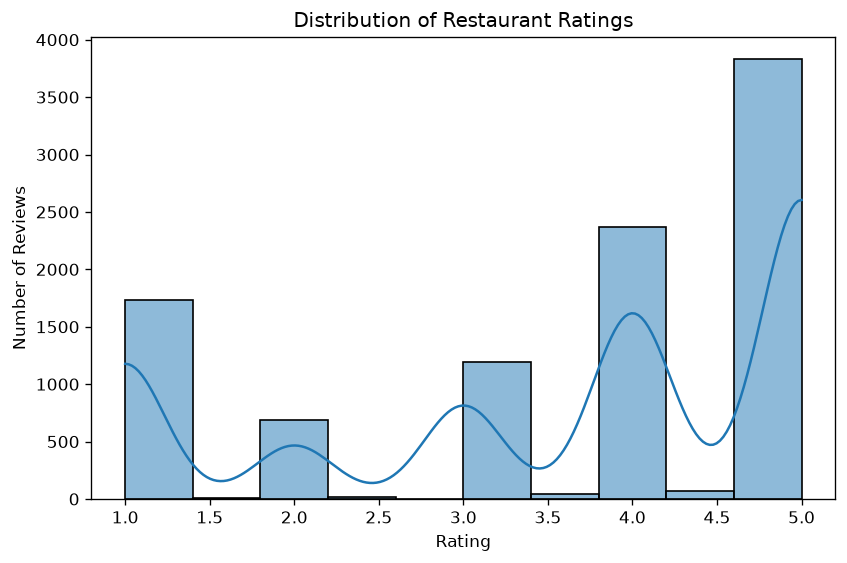

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(reviews_clean['Rating'].dropna(), bins=10, kde=True)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

**Why this chart was chosen**: A histogram was used to understand how customer ratings are distributed across the restaurant reviews.

**Insights**: The chart shows that ratings of 5.0 and 4.0 are the most frequent. Ratings of 1.0 are also noticeable, indicating that some customers had poor experiences. Overall, positive ratings are more common than low ratings.

**Business impact**: Restaurants can use rating distributions to understand customer satisfaction. Businesses with lower ratings can investigate service, food quality, and customer experience issues.

In [9]:
# Remove rows with empty review text
reviews_clean = reviews_clean.dropna(subset=['Review'])

# Convert reviews to lowercase
reviews_clean['Review'] = reviews_clean['Review'].astype(str).str.lower()

# Remove extra spaces
reviews_clean['Review'] = reviews_clean['Review'].str.strip()

print("Review text cleaning completed!")
print("Remaining reviews:", len(reviews_clean))

display(reviews_clean[['Review', 'Rating']].head(10))

Review text cleaning completed!
Remaining reviews: 9955


,Review,Rating
0,"the ambience was good, food was quite good . had saturday lunch , which was cost effective .\ngood place for a sate brunch. one can also chill with friends and or parents.\nwaiter soumen das was really courteous and helpful.",5.0
1,ambience is too good for a pleasant evening. service is very prompt. food is good. over all a good experience. soumen das - kudos to the service,5.0
2,a must try.. great food great ambience. thnx for the service by pradeep and subroto. my personal recommendation is penne alfredo pasta:) ....... also the music in the background is amazing.,5.0
3,"soumen das and arun was a great guy. only because of their behavior and sincerety, and good food off course, i would like to visit this place again.",5.0
4,food is good.we ordered kodi drumsticks and basket mutton biryani. all are good. thanks to pradeep. he served well. we enjoyed here. ambience is also very good.,5.0
5,"ambiance is good, service is good, food is apradeecp and subro best service\nfood is good. papiya good hostess and ur caption very good. this is 4star restaurant.",5.0
6,"its a very nice place, ambience is different, all the food we ordered was very tasty, service is also gud, worth visit. its reasonable as well. really a must visit place.",5.0
7,well after reading so many reviews finally visited this place...ambience was so good and coming to food crispy corn is nice. tawa fish was ok... basket biryani disappointed us... biryani was ok but not flattering as they claimed.. staff was polite and prompt especially pradeep and suman.,4.0
8,"excellent food , specially if you like spicy food . courteous staff . shubro and pradeep and papiya gave excellent service to our corporate team dinner . overall great for team dinners and party",5.0
9,"came for the birthday treat of a close friend. perfect place for a treat like this. very hospitable and cooperative staff. food was delicious, ambience was really good with the music and the lighting. chili honey lotus stem is a must try here. special mention to papiya who took good care of us.",5.0


In [10]:
print(reviews_clean['Rating'].value_counts().sort_index())

Rating
1.0    1735
1.5       9
2.0     684
2.5      19
3.0    1192
3.5      47
4.0    2373
4.5      69
5.0    3826
Name: count, dtype: int64


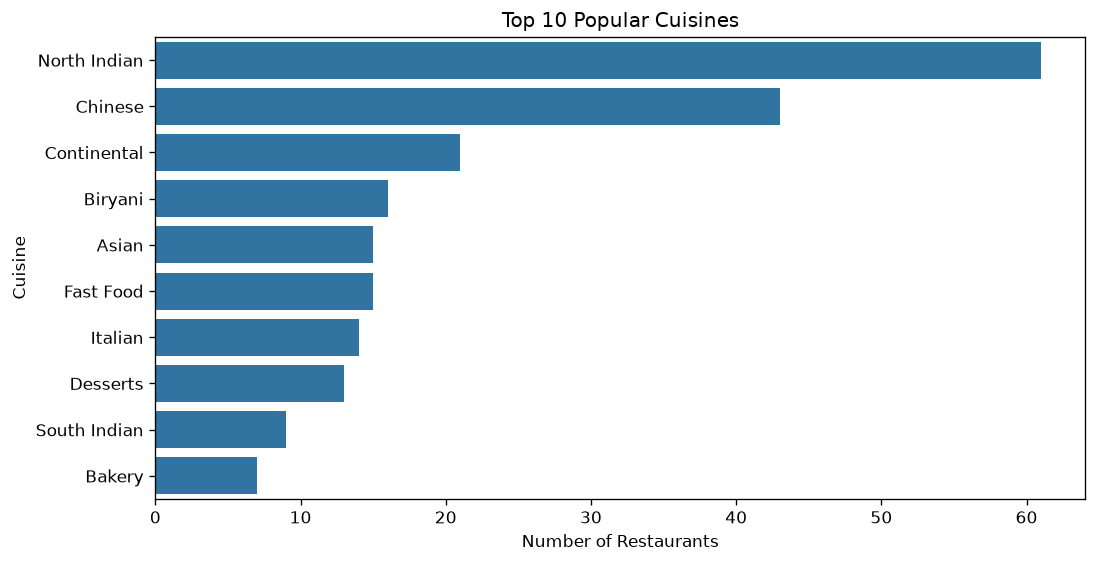

,count
Cuisines,
North Indian,61
Chinese,43
Continental,21
Biryani,16
Asian,15
Fast Food,15
Italian,14
Desserts,13
South Indian,9


In [11]:
# Analyze popular cuisines

cuisine_counts = (
    restaurants_clean['Cuisines']
    .dropna()
    .str.split(',')
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=cuisine_counts.values, y=cuisine_counts.index)

plt.title("Top 10 Popular Cuisines")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine")
plt.show()

display(cuisine_counts)

**Why this chart was chosen**: A horizontal bar chart was selected to compare the number of restaurants offering different cuisines.

**Insights**: North Indian cuisine leads with 61 restaurants, followed by Chinese cuisine with 43 and Continental cuisine with 21. Biryani, Asian, and Fast Food are also popular.

**Business** **impact**: Restaurant owners can use cuisine popularity to identify market demand and decide which food categories may attract more customers.

RESTAURANT COST SUMMARY
Cost analysis completed successfully!


,Cost
count,105.000000
mean,861.428571
std,510.149730
min,150.000000
25%,500.000000
50%,700.000000
75%,1200.000000
max,2800.000000


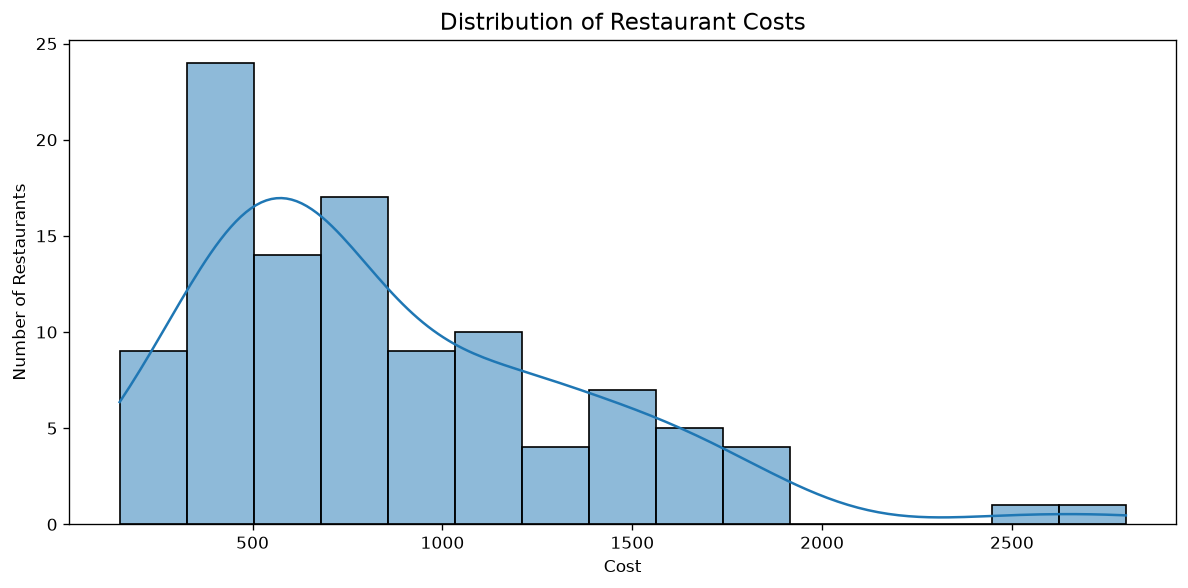

In [12]:
# Restaurant Cost Analysis

# Convert Cost column into numeric format
restaurants_clean['Cost'] = pd.to_numeric(
    restaurants_clean['Cost'].astype(str)
    .str.replace(',', '', regex=False)
    .str.extract(r'(\d+\.?\d*)')[0],
    errors='coerce'
)

# Display cost statistics
print("RESTAURANT COST SUMMARY")
display(restaurants_clean['Cost'].describe())

# Plot cost distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    restaurants_clean['Cost'].dropna(),
    bins=15,
    kde=True
)

plt.title("Distribution of Restaurant Costs", fontsize=14)
plt.xlabel("Cost")
plt.ylabel("Number of Restaurants")
plt.tight_layout()
plt.show()

print("Cost analysis completed successfully!")

**Why this chart was chosen**: A histogram with a density curve was used to understand the distribution of approximate restaurant costs.

**Insights**: Most restaurants fall within the lower-to-middle cost range, particularly around 500–1,000. A smaller number of restaurants have costs above 1,500, and a few are above 2,500. The distribution is right-skewed.

**Business impact**: This helps identify the dominant price range in the market and supports pricing and customer-segmentation decisions.

In [13]:
print(restaurants_clean['Cost'].describe())

count     105.000000
mean      861.428571
std       510.149730
min       150.000000
25%       500.000000
50%       700.000000
75%      1200.000000
max      2800.000000
Name: Cost, dtype: float64


TOP 10 RESTAURANTS BY AVERAGE RATING


,Restaurant,Average_Rating,Total_Reviews
3,AB's - Absolute Barbecues,4.88,100
11,B-Dubs,4.81,100
2,"3B's - Buddies, Bar & Barbecue",4.76,100
67,Paradise,4.70,100
35,Flechazo,4.66,100
87,The Indi Grill,4.60,100
97,Zega - Sheraton Hyderabad Hotel,4.45,100
64,Over The Moon Brew Company,4.34,100
16,Beyond Flavours,4.28,100
19,Cascade - Radisson Hyderabad Hitec City,4.26,100


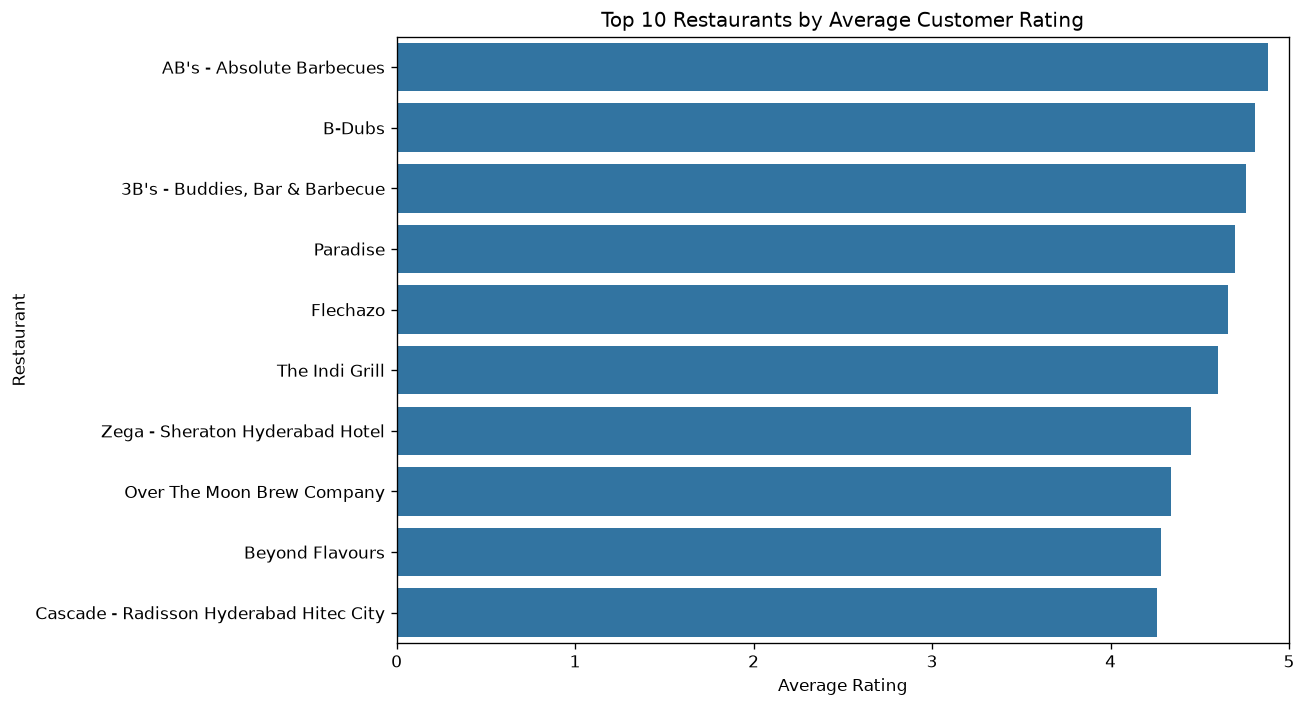

In [14]:
# Restaurant Rating Analysis

# Calculate average rating and number of reviews
restaurant_ratings = (
    reviews_clean.dropna(subset=['Rating'])
    .groupby('Restaurant')
    .agg(
        Average_Rating=('Rating', 'mean'),
        Total_Reviews=('Rating', 'count')
    )
    .reset_index()
)

# Consider restaurants with at least 3 reviews
restaurant_ratings = restaurant_ratings[
    restaurant_ratings['Total_Reviews'] >= 3
]

# Display top 10 restaurants
top_restaurants = restaurant_ratings.sort_values(
    by='Average_Rating', ascending=False
).head(10)

print("TOP 10 RESTAURANTS BY AVERAGE RATING")
display(top_restaurants)

# Visualize results
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_restaurants,
    x='Average_Rating',
    y='Restaurant'
)

plt.title("Top 10 Restaurants by Average Customer Rating")
plt.xlabel("Average Rating")
plt.ylabel("Restaurant")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

**Why this chart was chosen**: A horizontal bar chart was used to compare restaurants based on their average customer ratings.

**Insights**: AB's - Absolute Barbecues has the highest average rating at 4.88, followed by B-Dubs at 4.81 and 3B's - Buddies, Bar & Barbecue at 4.76. The selected restaurants have at least three reviews.

**Business impact**: This analysis helps identify restaurants with strong customer satisfaction that can be studied for successful practices.

In [15]:
# Combine restaurant details and customer ratings

# Create matching restaurant names
restaurants_clean['Name_Key'] = (
    restaurants_clean['Name'].astype(str).str.strip().str.lower()
)

restaurant_ratings['Name_Key'] = (
    restaurant_ratings['Restaurant'].astype(str).str.strip().str.lower()
)

# Merge datasets
zomato = pd.merge(
    restaurants_clean,
    restaurant_ratings,
    on='Name_Key',
    how='inner'
)

# Display results
print("Combined dataset created successfully!")
print("Combined dataset shape:", zomato.shape)

display(zomato.head(10))

print("Columns:", zomato.columns.tolist())

Combined dataset created successfully!
Combined dataset shape: (100, 10)
Columns: ['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings', 'Name_Key', 'Restaurant', 'Average_Rating', 'Total_Reviews']


,Name,Links,Cost,Collections,Cuisines,Timings,Name_Key,Restaurant,Average_Rating,Total_Reviews
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,800,"Food Hygiene Rated Restaurants in Hyderabad, Corporate Favorites, Great Buffets, Top-Rated, Gold Curated, Live Sports Screenings","Chinese, Continental, Kebab, European, South Indian, North Indian","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)",beyond flavours,Beyond Flavours,4.280,100
1,Paradise,https://www.zomato.com/hyderabad/paradise-gachibowli,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM,paradise,Paradise,4.700,100
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gachibowli,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM",flechazo,Flechazo,4.660,100
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-hotel-restaurant-gachibowli,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Beverages",12 Noon to 2 AM,shah ghouse hotel & restaurant,Shah Ghouse Hotel & Restaurant,3.210,100
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon-brew-company-gachibowli,1200,"Best Bars & Pubs, Food Hygiene Rated Restaurants in Hyderabad, Top-Rated, Gold Curated, Hyderabad's Hottest","Asian, Continental, North Indian, Chinese, Mediterranean","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12noon to 12midnight (Fri-Sat)",over the moon brew company,Over The Moon Brew Company,4.340,100
5,The Fisherman's Wharf,https://www.zomato.com/hyderabad/the-fishermans-wharf-gachibowli,1500,"Sunday Brunches, Corporate Favorites, Great Buffets, Hyderabad's Hottest, Food Hygiene Rated Restaurants in Hyderabad, Top-Rated, Gold Curated","Seafood, Goan, North Indian, Continental, Asian","12Noon to 3:30PM, 4PM to 6:30PM, 7PM to 11:30PM (Mon, Tue, Wed, Thu, Sun), 12Noon to 3:30PM, 4PM to 6:30PM, 7PM to 12Midnight (Fri-Sat)",the fisherman's wharf,The Fisherman's Wharf,4.220,100
6,eat.fit,https://www.zomato.com/hyderabad/eat-fit-gachibowli,500,Food Hygiene Rated Restaurants in Hyderabad,"Healthy Food, North Indian, Continental, South Indian",7 AM to 10 PM,eat.fit,eat.fit,3.200,100
7,Shah Ghouse Spl Shawarma,https://www.zomato.com/hyderabad/shah-ghouse-spl-shawarma-gachibowli,300,NaN,Lebanese,12 Noon to 12 Midnight,shah ghouse spl shawarma,Shah Ghouse Spl Shawarma,3.430,100
8,Hyper Local,https://www.zomato.com/hyderabad/hyper-local-gachibowli,1000,"Great Buffets, Live Sports Screenings, Best Bars & Pubs, Trending This Week","American, Chinese, North Indian, Kebab, South Indian",12 Noon to 12 Midnight,hyper local,Hyper Local,3.640,100
9,Cream Stone,https://www.zomato.com/hyderabad/cream-stone-gachibowli,350,Frozen Delights,"Ice Cream, Desserts","10 AM to 1 AM (Mon-Thu), 10 AM to 1:30 AM (Fri-Sun)",cream stone,Cream Stone,3.845,100


In [16]:
print("Restaurants in metadata:", len(restaurants_clean))
print("Restaurants with ratings:", len(restaurant_ratings))
print("Successfully matched restaurants:", len(zomato))

Restaurants in metadata: 105
Restaurants with ratings: 100
Successfully matched restaurants: 100


In [17]:
# Check available numerical features

print("Available columns:")
print(zomato.columns.tolist())

print("\nMissing values:")
print(zomato[['Cost', 'Average_Rating', 'Total_Reviews']].isnull().sum())

print("\nNumerical feature summary:")
display(zomato[['Cost', 'Average_Rating', 'Total_Reviews']].describe())

Available columns:
['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings', 'Name_Key', 'Restaurant', 'Average_Rating', 'Total_Reviews']

Missing values:
Cost              0
Average_Rating    0
Total_Reviews     0
dtype: int64

Numerical feature summary:


,Cost,Average_Rating,Total_Reviews
count,100.000000,100.000000,100.00000
mean,872.000000,3.601891,99.54000
std,505.940468,0.508100,2.73924
min,150.000000,2.400000,77.00000
25%,500.000000,3.245000,100.00000
50%,700.000000,3.613081,100.00000
75%,1200.000000,3.846250,100.00000
max,2800.000000,4.880000,100.00000


In [18]:
# Select features for clustering
features = ['Cost', 'Average_Rating', 'Total_Reviews']

# Create a clean dataset
cluster_data = zomato[features].copy()

# Remove missing and infinite values
cluster_data = cluster_data.replace([np.inf, -np.inf], np.nan)
cluster_data = cluster_data.dropna()

print("Clustering data prepared!")
print("Number of restaurants:", len(cluster_data))

display(cluster_data.head())

Clustering data prepared!
Number of restaurants: 100


,Cost,Average_Rating,Total_Reviews
0,800,4.28,100
1,800,4.70,100
2,1300,4.66,100
3,800,3.21,100
4,1200,4.34,100


### Feature Engineering and Feature Scaling

Feature engineering was performed to create meaningful numerical features for restaurant clustering.

The following features were used:

- **Cost:** Average cost of dining at a restaurant.
- **Average Rating:** Average customer rating calculated from customer reviews.
- **Total Reviews:** Number of customer reviews available for each restaurant.

The three numerical features were selected to understand how restaurant pricing, customer satisfaction, and review activity relate to each other.

**Feature Scaling:** StandardScaler was used to standardize the numerical features so that variables with larger numerical ranges would not dominate the clustering process.

In [19]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(cluster_data)

scaled_df = pd.DataFrame(
    scaled_features,
    columns=features,
    index=cluster_data.index
)

print("Feature scaling completed!")
display(scaled_df.head())

Feature scaling completed!


,Cost,Average_Rating,Total_Reviews
0,-0.143026,1.341321,0.168776
1,-0.143026,2.172093,0.168776
2,0.850211,2.092972,0.168776
3,-0.143026,-0.775171,0.168776
4,0.651564,1.460002,0.168776


## 2. Understanding the Variables

The clustering uses three numeric fields: approximate restaurant cost, mean customer rating, and review count. Restaurant name is used only to join metadata to review aggregates. Review text is analyzed separately for sentiment.


## 3. Data Wrangling and Feature Preparation

Duplicate records and inconsistent text spacing are handled, ratings and costs are converted to numeric values, and review ratings are aggregated by restaurant before the datasets are joined. Rows without usable clustering features are excluded. The selected features are standardized because cost and ratings use different scales.


## 4. Exploratory Charts and Restaurant Clustering

The exploratory charts below preserve the original analysis and plots. Charts 14 and 15 are implemented here and include their business interpretation.


#### Chart 14 — Correlation Heatmap

**Why this chart:** A heatmap summarizes pairwise linear relationships among the three numeric clustering features.


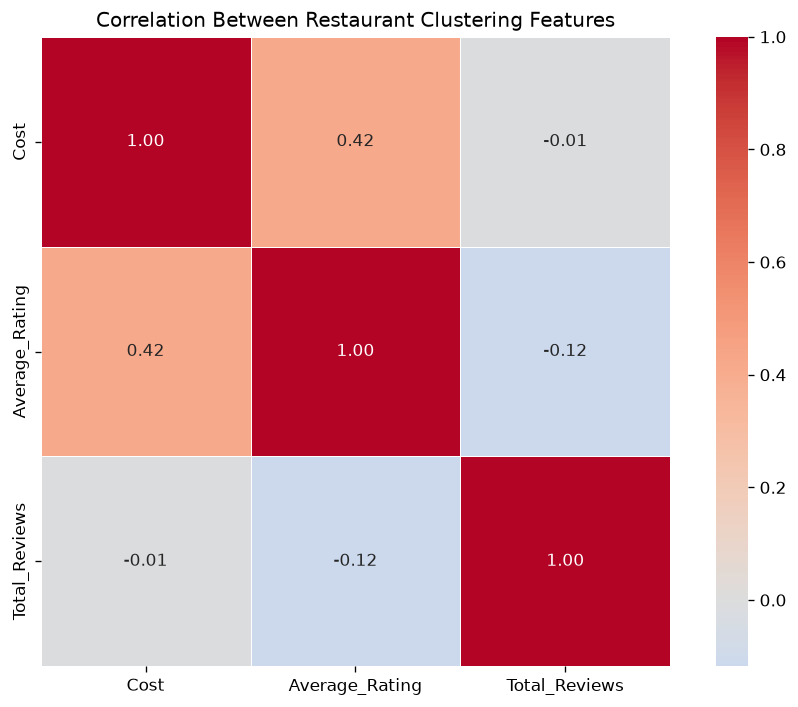

In [20]:
# Chart 14: Correlation among the clustering variables
correlation_matrix = cluster_data[features].corr(method="pearson")
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation Between Restaurant Clustering Features")
plt.tight_layout()
plt.show()


**Insight and business impact:** Read the annotated values to see whether higher cost or review volume tends to move with higher ratings in this sample. A weak relationship means price or popularity alone is not a reliable proxy for satisfaction; businesses should assess these measures separately. Correlation is descriptive and does not establish cause.


## 5. Clustering Models, Evaluation, and Tuning

K-Means, Agglomerative Clustering, and DBSCAN are compared with internal clustering metrics. Since there is no labeled target, the tuning step tests candidate cluster counts using silhouette score and inertia; it does not use supervised cross-validation.


## Machine Learning Algorithms

Unsupervised machine learning techniques were used to group restaurants based on similarities in cost, average customer ratings, and review activity.

### 1. K-Means Clustering

K-Means is a centroid-based clustering algorithm that divides data points into a specified number of clusters. It assigns restaurants to groups based on their similarity to cluster centroids.

In this project, K-Means was used to identify groups of restaurants with similar pricing, customer ratings, and review activity.

### 2. Agglomerative Clustering

Agglomerative Clustering is a hierarchical clustering technique. It starts by treating each data point as an individual cluster and gradually merges similar clusters until the required number of clusters is reached.

It was used to compare hierarchical grouping results with K-Means.

### 3. DBSCAN

DBSCAN is a density-based clustering algorithm that groups closely packed data points and identifies isolated points as noise or outliers.

It was used to explore density-based restaurant groups and detect restaurants that did not fit into dense clusters.

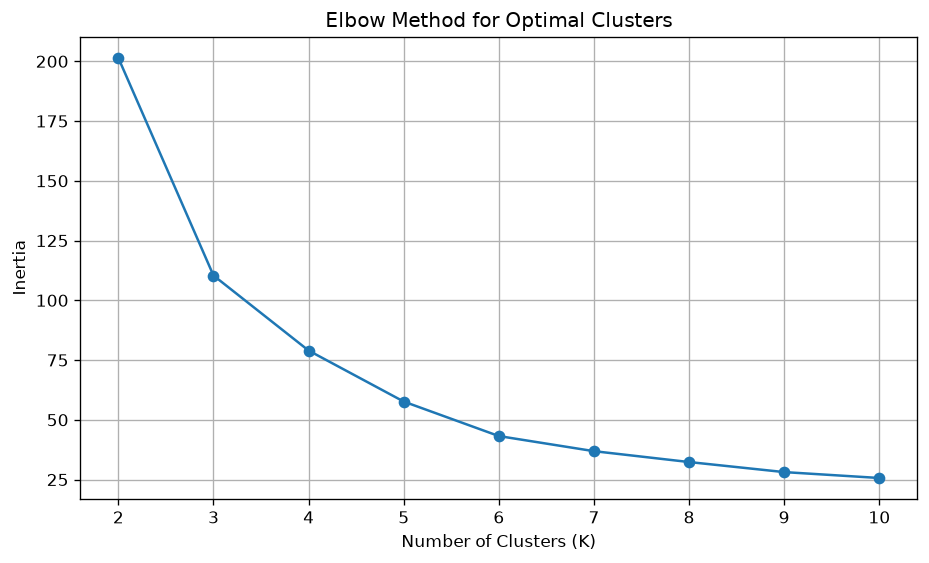

In [21]:
from sklearn.cluster import KMeans

inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(range(2, 11), inertia, marker='o')

plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

**Why this chart was chosen**: The Elbow Method was used to examine how K-Means inertia changes as the number of clusters increases.

**Insights**: Inertia decreases as more clusters are added. The reduction becomes less pronounced after approximately three or four clusters, suggesting that adding more clusters gives smaller improvements.

**Business impact**: Selecting a reasonable number of clusters helps create useful restaurant segments without making the model unnecessarily complicated.

In [22]:
# K-Means Clustering Model

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(scaled_features)

# Add cluster labels to the dataset
cluster_data = cluster_data.copy()
cluster_data['Cluster'] = cluster_labels

print("K-Means model trained successfully!")
print("\nRestaurants in each cluster:")
print(cluster_data['Cluster'].value_counts().sort_index())

# Evaluate model
silhouette = silhouette_score(scaled_features, cluster_labels)

print("\nSilhouette Score:", round(silhouette, 4))

K-Means model trained successfully!

Restaurants in each cluster:
Cluster
0    19
1    25
2    54
3     2
Name: count, dtype: int64

Silhouette Score: 0.3797


#### Chart 15 — Pair Plot of K-Means Features

**Why this chart:** Pairwise scatter plots show how the three clustering features vary together, with color identifying the four-cluster exploratory K-Means assignments.


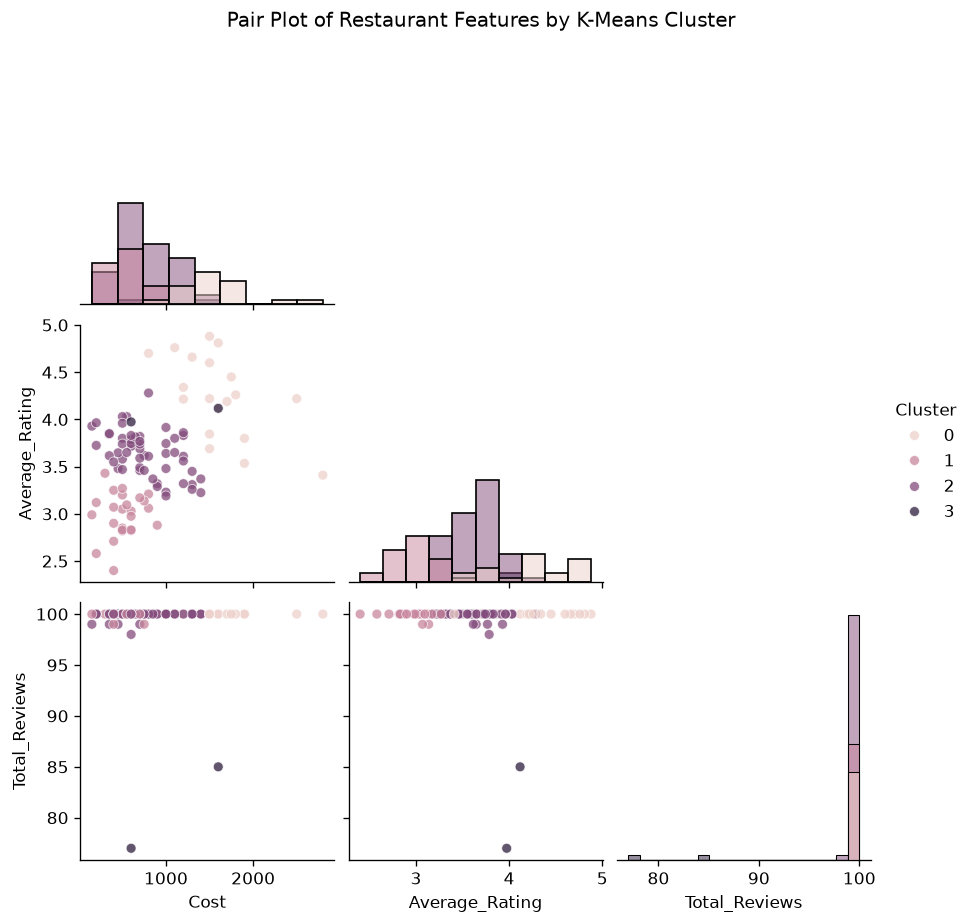

In [23]:
# Chart 15: Pairwise feature relationships colored by the exploratory K-Means labels
pair_grid = sns.pairplot(cluster_data, vars=features, hue="Cluster", diag_kind="hist", corner=True, plot_kws={"alpha": 0.75, "s": 35})
pair_grid.fig.suptitle("Pair Plot of Restaurant Features by K-Means Cluster", y=1.02)
plt.show()


**Insight and business impact:** The pair plot reveals which feature combinations drive separation and whether groups overlap. This helps operators compare restaurants on price, rating, and review activity together, while overlap warns that cluster labels are broad profiles rather than definitive business categories.


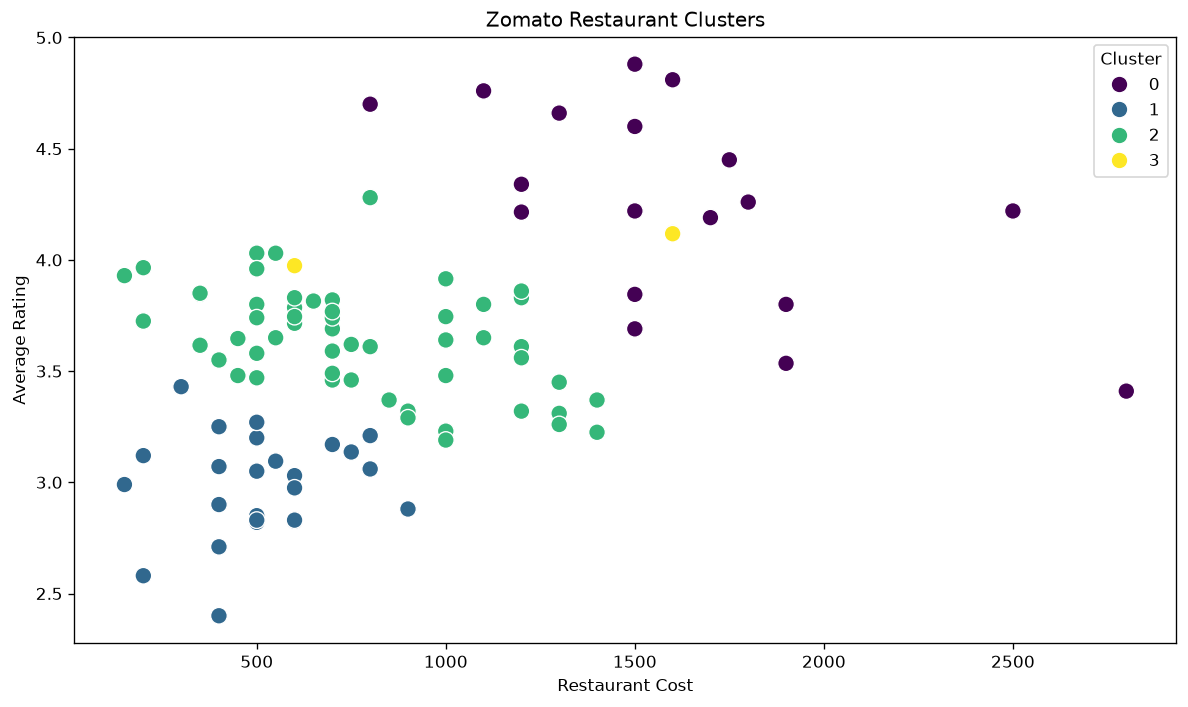

In [24]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cluster_data,
    x='Cost',
    y='Average_Rating',
    hue='Cluster',
    palette='viridis',
    s=100
)

plt.title("Zomato Restaurant Clusters")
plt.xlabel("Restaurant Cost")
plt.ylabel("Average Rating")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

### Four-Cluster K-Means View

The scatter plot shows the four exploratory K-Means groups using restaurant cost and average rating. The full model also includes review count, so overlap in this two-dimensional view is expected. Cluster identifiers are arbitrary labels, not rankings. The rare group should be interpreted cautiously.


In [25]:
# Analyze restaurant clusters

cluster_summary = cluster_data.groupby('Cluster').agg(
    Number_of_Restaurants=('Cost', 'count'),
    Average_Cost=('Cost', 'mean'),
    Average_Rating=('Average_Rating', 'mean'),
    Average_Reviews=('Total_Reviews', 'mean')
).round(2)

print("RESTAURANT CLUSTER SUMMARY")
display(cluster_summary)

RESTAURANT CLUSTER SUMMARY


,Number_of_Restaurants,Average_Cost,Average_Rating,Average_Reviews
Cluster,,,,
0,19,1613.16,4.25,100.00
1,25,510.00,2.99,99.92
2,54,770.37,3.64,99.89
3,2,1100.00,4.05,81.00


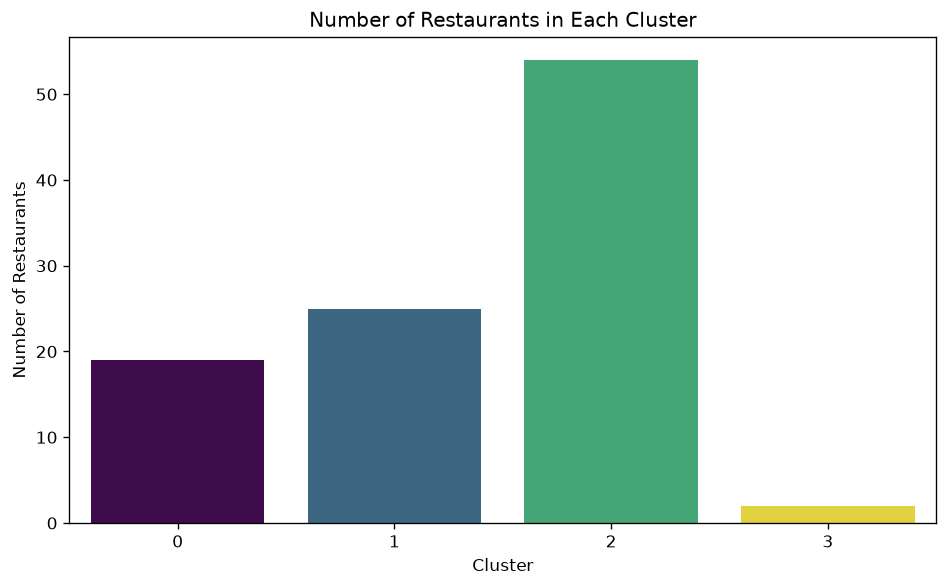

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=cluster_data,
    x='Cluster',
    hue='Cluster',
    palette='viridis',
    legend=False
)

plt.title("Number of Restaurants in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Restaurants")
plt.tight_layout()
plt.show()

**Why this chart:** A count plot compares the number of restaurants assigned to each exploratory cluster.

**Insight and business impact:** The plotted counts show whether restaurant profiles are common or rare in this sample. A small group may be useful for identifying unusual profiles, but it is too small to support broad business conclusions without further validation.


## Final Cluster Analysis and Interpretation

The corrected final K-Means workflow clusters restaurants using only Cost, Average_Rating and Total_Reviews. It assigns 24, 74 and 2 restaurants to the three groups. K-Means minimizes within-cluster distances and does not enforce equal group sizes. The 74-restaurant group reflects the dominant feature pattern in this 100-restaurant matched sample.

The two-restaurant cluster is a small, distinct profile, not evidence of a broad market segment. Its average cost is approximately ₹1,100, average rating 4.05 and average review count 81. Inspect the two restaurants individually and validate the pattern with additional data before taking action. Cluster sizes describe this dataset; they do not measure customer demand or business performance.

A previous exploratory rerun accidentally included earlier cluster labels in the tuning features and reported a different split. That leakage has been removed: the final scaling and tuning use only the original three features, and the verified result is 24 / 74 / 2 with a K-Means silhouette score of 0.4673.


In [27]:
print("FINAL CLUSTER SUMMARY")

cluster_summary = cluster_data.groupby('Cluster').agg(
    Number_of_Restaurants=('Cost', 'count'),
    Average_Cost=('Cost', 'mean'),
    Average_Rating=('Average_Rating', 'mean'),
    Average_Reviews=('Total_Reviews', 'mean')
).round(2)

display(cluster_summary)

FINAL CLUSTER SUMMARY


,Number_of_Restaurants,Average_Cost,Average_Rating,Average_Reviews
Cluster,,,,
0,19,1613.16,4.25,100.00
1,25,510.00,2.99,99.92
2,54,770.37,3.64,99.89
3,2,1100.00,4.05,81.00


In [28]:
# K-Means Model Evaluation

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

silhouette = silhouette_score(
    scaled_features, cluster_labels
)

davies = davies_bouldin_score(
    scaled_features, cluster_labels
)

calinski = calinski_harabasz_score(
    scaled_features, cluster_labels
)

print("K-MEANS EVALUATION RESULTS")
print("--------------------------------")
print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Score:", round(davies, 4))
print("Calinski-Harabasz Score:", round(calinski, 4))

K-MEANS EVALUATION RESULTS
--------------------------------
Silhouette Score: 0.3797
Davies-Bouldin Score: 0.7645
Calinski-Harabasz Score: 89.556


In [29]:
# Hierarchical Clustering

from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

hierarchical_labels = hierarchical.fit_predict(scaled_features)

# Evaluate Hierarchical Clustering
h_silhouette = silhouette_score(
    scaled_features, hierarchical_labels
)

h_davies = davies_bouldin_score(
    scaled_features, hierarchical_labels
)

h_calinski = calinski_harabasz_score(
    scaled_features, hierarchical_labels
)

print("HIERARCHICAL CLUSTERING RESULTS")
print("--------------------------------")
print("Silhouette Score:", round(h_silhouette, 4))
print("Davies-Bouldin Score:", round(h_davies, 4))
print("Calinski-Harabasz Score:", round(h_calinski, 4))

HIERARCHICAL CLUSTERING RESULTS
--------------------------------
Silhouette Score: 0.3692
Davies-Bouldin Score: 0.7409
Calinski-Harabasz Score: 82.575


In [30]:
# DBSCAN Clustering

from sklearn.cluster import DBSCAN

eps_values = [0.3, 0.5, 0.7, 0.9, 1.1, 1.3]

print("DBSCAN PARAMETER ANALYSIS")
print("-" * 50)

for eps in eps_values:

    dbscan = DBSCAN(eps=eps, min_samples=5)

    labels = dbscan.fit_predict(scaled_features)

    clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise = list(labels).count(-1)

    print(f"\nEpsilon: {eps}")
    print("Number of clusters:", clusters)
    print("Noise points:", noise)

    # Calculate silhouette only when valid
    valid_labels = labels[labels != -1]
    valid_data = scaled_features[labels != -1]

    if len(set(valid_labels)) >= 2 and len(valid_labels) > len(set(valid_labels)):
        score = silhouette_score(valid_data, valid_labels)
        print("Silhouette Score (excluding noise):", round(score, 4))
    else:
        print("Silhouette Score: Not applicable")

DBSCAN PARAMETER ANALYSIS
--------------------------------------------------

Epsilon: 0.3
Number of clusters: 5
Noise points: 44
Silhouette Score (excluding noise): 0.5098

Epsilon: 0.5
Number of clusters: 1
Noise points: 24
Silhouette Score: Not applicable

Epsilon: 0.7
Number of clusters: 1
Noise points: 8
Silhouette Score: Not applicable

Epsilon: 0.9
Number of clusters: 1
Noise points: 4
Silhouette Score: Not applicable

Epsilon: 1.1
Number of clusters: 1
Noise points: 4
Silhouette Score: Not applicable

Epsilon: 1.3
Number of clusters: 1
Noise points: 4
Silhouette Score: Not applicable


DBSCAN CLUSTER DISTRIBUTION
DBSCAN_Cluster
-1    44
 0     8
 1    14
 2    20
 3     6
 4     8
Name: count, dtype: int64


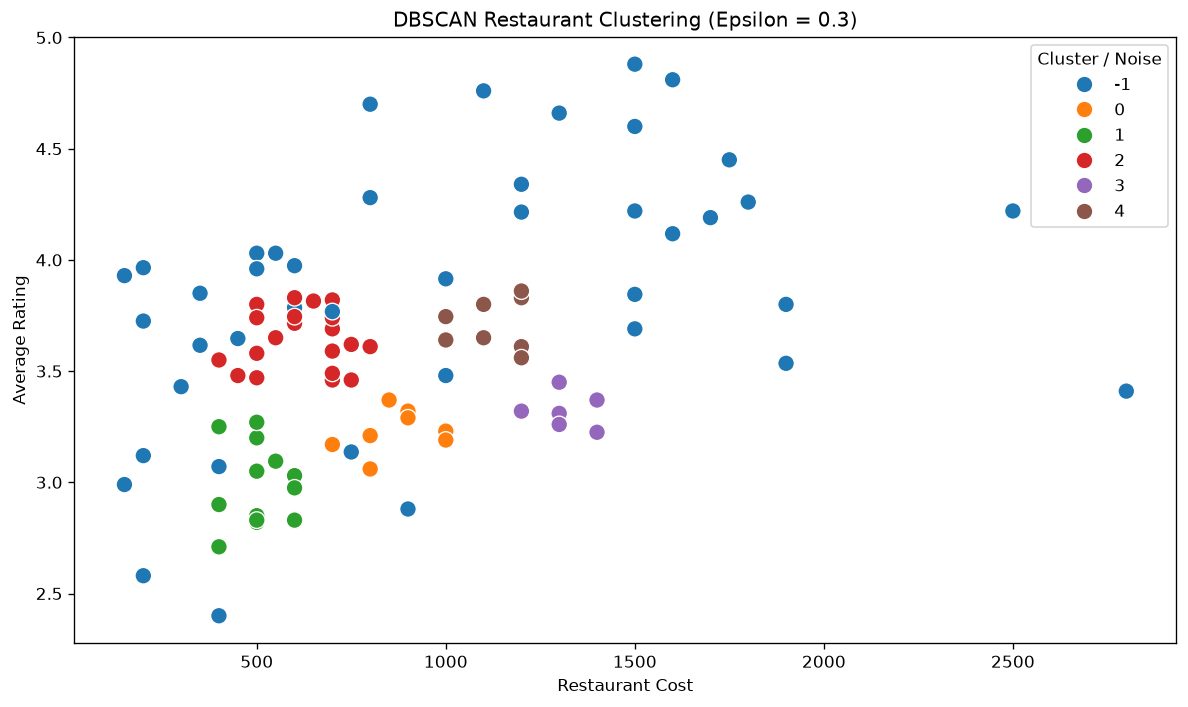

In [31]:
# Final DBSCAN Model

dbscan_final = DBSCAN(eps=0.3, min_samples=5)

dbscan_labels = dbscan_final.fit_predict(scaled_features)

# Add DBSCAN labels
dbscan_results = cluster_data.copy()
dbscan_results['DBSCAN_Cluster'] = dbscan_labels

print("DBSCAN CLUSTER DISTRIBUTION")
print(dbscan_results['DBSCAN_Cluster'].value_counts().sort_index())

# Visualize clusters and noise
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=dbscan_results,
    x='Cost',
    y='Average_Rating',
    hue='DBSCAN_Cluster',
    palette='tab10',
    s=100
)

plt.title("DBSCAN Restaurant Clustering (Epsilon = 0.3)")
plt.xlabel("Restaurant Cost")
plt.ylabel("Average Rating")
plt.legend(title="Cluster / Noise")
plt.tight_layout()
plt.show()

**Why this chart was chosen**: A scatter plot was used to visualise the clusters identified by DBSCAN and distinguish noise points from clustered restaurants.

**Insights**: With epsilon set to 0.3 and minimum samples set to 5, DBSCAN identifies five clusters and 44 noise points. The noise points indicate restaurants that do not fit closely into the identified dense groups.

**Business impact**: DBSCAN helps identify unusual restaurant profiles that may require separate investigation.

## Model Evaluation and Comparison

The clustering algorithms were evaluated using internal clustering evaluation metrics to understand the quality and separation of the generated clusters.

The following metrics were considered:

- **Silhouette Score:** Measures how similar a data point is to its own cluster compared with other clusters. A higher score indicates better-defined clusters.
- **Davies-Bouldin Index:** Measures the average similarity between clusters. A lower score indicates better cluster separation.
- **Calinski-Harabasz Index:** Measures the ratio of between-cluster dispersion to within-cluster dispersion. A higher score generally indicates better-defined clusters.

For a fair comparison, K-Means and Agglomerative Clustering are evaluated with K=3 using all restaurants. DBSCAN metrics are calculated only for non-noise observations because DBSCAN labels outliers as noise (-1).

**Note:** The DBSCAN silhouette score was calculated only for non-noise observations, so it should not be directly compared with scores calculated using all observations for the other algorithms.

In [32]:
# Fair model comparison: K-Means K=3, Agglomerative K=3, and DBSCAN
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Fit both partition-based models using the same scaled observations and K=3.
kmeans_k3_labels = KMeans(
    n_clusters=3, random_state=42, n_init=10
).fit_predict(scaled_features)

agglo_k3_labels = AgglomerativeClustering(
    n_clusters=3, linkage='ward'
).fit_predict(scaled_features)

def calculate_metrics(data, labels):
    # Internal clustering metrics require at least 2 clusters and fewer
    # clusters than observations.
    if len(set(labels)) < 2 or len(set(labels)) >= len(labels):
        return (np.nan, np.nan, np.nan)
    return (
        silhouette_score(data, labels),
        davies_bouldin_score(data, labels),
        calinski_harabasz_score(data, labels)
    )

km_sil, km_db, km_ch = calculate_metrics(scaled_features, kmeans_k3_labels)
ag_sil, ag_db, ag_ch = calculate_metrics(scaled_features, agglo_k3_labels)

# DBSCAN metrics are calculated only on observations that are not labelled noise.
dbscan_mask = dbscan_labels != -1
dbscan_non_noise_labels = dbscan_labels[dbscan_mask]
db_sil, db_db, db_ch = calculate_metrics(
    scaled_features[dbscan_mask], dbscan_non_noise_labels
)

comparison = pd.DataFrame([
    {
        'Model': 'K-Means (K=3)',
        'Silhouette Score': km_sil,
        'Davies-Bouldin Score': km_db,
        'Calinski-Harabasz Score': km_ch,
        'Evaluation Set': 'All restaurants'
    },
    {
        'Model': 'Agglomerative (K=3)',
        'Silhouette Score': ag_sil,
        'Davies-Bouldin Score': ag_db,
        'Calinski-Harabasz Score': ag_ch,
        'Evaluation Set': 'All restaurants'
    },
    {
        'Model': 'DBSCAN (eps=0.3)',
        'Silhouette Score': db_sil,
        'Davies-Bouldin Score': db_db,
        'Calinski-Harabasz Score': db_ch,
        'Evaluation Set': f'Non-noise restaurants only ({dbscan_mask.sum()} of {len(dbscan_mask)})'
    }
])

print("CLUSTERING MODEL COMPARISON")
display(comparison.round(4))
print(
    "Note: DBSCAN metrics exclude noise observations (-1), so they are not "
    "directly comparable with K-Means and Agglomerative metrics calculated "
    "using all restaurants."
)


CLUSTERING MODEL COMPARISON
Note: DBSCAN metrics exclude noise observations (-1), so they are not directly comparable with K-Means and Agglomerative metrics calculated using all restaurants.


,Model,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score,Evaluation Set
0,K-Means (K=3),0.4673,0.7071,83.3246,All restaurants
1,Agglomerative (K=3),0.4181,0.7897,80.7440,All restaurants
2,DBSCAN (eps=0.3),0.5098,0.6036,82.6095,Non-noise restaurants only (56 of 100)


## 6. Customer Review Sentiment Analysis

VADER labels the review text as positive, neutral, or negative. Its lexicon-based results are useful for an overview, but can miss sarcasm, context, and local-language expressions.


In [33]:
# Customer Review Sentiment Analysis

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def get_sentiment(text):
    score = analyzer.polarity_scores(str(text))['compound']

    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

reviews_clean['Sentiment'] = reviews_clean['Review'].apply(get_sentiment)

print("SENTIMENT ANALYSIS COMPLETED")
print(reviews_clean['Sentiment'].value_counts())

display(reviews_clean[['Review', 'Sentiment']].head(10))

SENTIMENT ANALYSIS COMPLETED
Sentiment
Positive    7392
Negative    1846
Neutral      717
Name: count, dtype: int64


,Review,Sentiment
0,"the ambience was good, food was quite good . had saturday lunch , which was cost effective .\ngood place for a sate brunch. one can also chill with friends and or parents.\nwaiter soumen das was really courteous and helpful.",Positive
1,ambience is too good for a pleasant evening. service is very prompt. food is good. over all a good experience. soumen das - kudos to the service,Positive
2,a must try.. great food great ambience. thnx for the service by pradeep and subroto. my personal recommendation is penne alfredo pasta:) ....... also the music in the background is amazing.,Positive
3,"soumen das and arun was a great guy. only because of their behavior and sincerety, and good food off course, i would like to visit this place again.",Positive
4,food is good.we ordered kodi drumsticks and basket mutton biryani. all are good. thanks to pradeep. he served well. we enjoyed here. ambience is also very good.,Positive
5,"ambiance is good, service is good, food is apradeecp and subro best service\nfood is good. papiya good hostess and ur caption very good. this is 4star restaurant.",Positive
6,"its a very nice place, ambience is different, all the food we ordered was very tasty, service is also gud, worth visit. its reasonable as well. really a must visit place.",Positive
7,well after reading so many reviews finally visited this place...ambience was so good and coming to food crispy corn is nice. tawa fish was ok... basket biryani disappointed us... biryani was ok but not flattering as they claimed.. staff was polite and prompt especially pradeep and suman.,Positive
8,"excellent food , specially if you like spicy food . courteous staff . shubro and pradeep and papiya gave excellent service to our corporate team dinner . overall great for team dinners and party",Positive
9,"came for the birthday treat of a close friend. perfect place for a treat like this. very hospitable and cooperative staff. food was delicious, ambience was really good with the music and the lighting. chili honey lotus stem is a must try here. special mention to papiya who took good care of us.",Positive


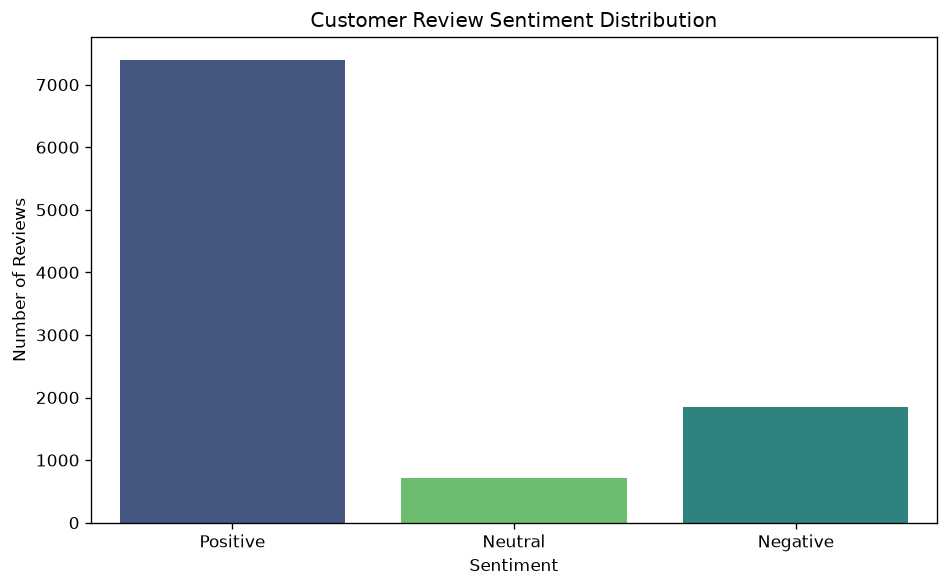

In [34]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=reviews_clean,
    x='Sentiment',
    hue='Sentiment',
    order=['Positive', 'Neutral', 'Negative'],
    palette='viridis',
    legend=False
)

plt.title("Customer Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

**Why this chart was chosen**: A count plot was used to compare positive, negative, and neutral customer reviews identified using VADER sentiment analysis.

**Insights**: Out of 9,955 reviews, 7,392 (74.25%) are positive, 1,846 (18.54%) are negative, and 717 (7.20%) are neutral. Positive reviews form the largest category.

**Business impact**: Restaurants can monitor customer sentiment to understand overall satisfaction and identify areas requiring improvement.

In [35]:
sentiment_counts = reviews_clean['Sentiment'].value_counts()

sentiment_percentages = (
    reviews_clean['Sentiment'].value_counts(normalize=True) * 100
)

sentiment_summary = pd.DataFrame({
    'Number of Reviews': sentiment_counts,
    'Percentage': sentiment_percentages.round(2)
})

display(sentiment_summary)

,Number of Reviews,Percentage
Sentiment,,
Positive,7392,74.25
Negative,1846,18.54
Neutral,717,7.20


In [36]:
restaurant_sentiment = pd.crosstab(
    reviews_clean['Restaurant'],
    reviews_clean['Sentiment']
)

restaurant_sentiment['Total_Reviews'] = restaurant_sentiment.sum(axis=1)

display(restaurant_sentiment.head(10))

Sentiment,Negative,Neutral,Positive,Total_Reviews
Restaurant,,,,
10 Downing Street,13,2,85,100
13 Dhaba,16,18,66,100
"3B's - Buddies, Bar & Barbecue",5,1,94,100
AB's - Absolute Barbecues,1,0,99,100
Absolute Sizzlers,20,3,77,100
Al Saba Restaurant,25,16,58,99
American Wild Wings,11,0,66,77
Amul,15,20,64,99
Arena Eleven,9,0,76,85


In [37]:
# Calculate sentiment percentages for each restaurant
restaurant_sentiment['Positive_Percentage'] = (
    restaurant_sentiment['Positive'] /
    restaurant_sentiment['Total_Reviews'] * 100
)

restaurant_sentiment['Negative_Percentage'] = (
    restaurant_sentiment['Negative'] /
    restaurant_sentiment['Total_Reviews'] * 100
)

# Consider restaurants with at least 50 reviews
filtered_restaurants = restaurant_sentiment[
    restaurant_sentiment['Total_Reviews'] >= 50
]

# Top 10 restaurants by positive sentiment
top_positive = filtered_restaurants.sort_values(
    'Positive_Percentage', ascending=False
).head(10)

# Top 10 restaurants by negative sentiment
top_negative = filtered_restaurants.sort_values(
    'Negative_Percentage', ascending=False
).head(10)

print("TOP 10 POSITIVE RESTAURANTS")
display(top_positive)

print("TOP 10 NEGATIVE RESTAURANTS")
display(top_negative)

TOP 10 POSITIVE RESTAURANTS
TOP 10 NEGATIVE RESTAURANTS


Sentiment,Negative,Neutral,Positive,Total_Reviews,Positive_Percentage,Negative_Percentage
Restaurant,,,,,,
AB's - Absolute Barbecues,1,0,99,100,99.0,1.0
The Indi Grill,1,0,99,100,99.0,1.0
B-Dubs,2,0,98,100,98.0,2.0
Flechazo,4,0,96,100,96.0,4.0
Paradise,3,1,96,100,96.0,3.0
Zega - Sheraton Hyderabad Hotel,4,0,96,100,96.0,4.0
Mazzo - Marriott Executive Apartments,5,0,95,100,95.0,5.0
"3B's - Buddies, Bar & Barbecue",5,1,94,100,94.0,5.0
Feast - Sheraton Hyderabad Hotel,6,0,94,100,94.0,6.0


Sentiment,Negative,Neutral,Positive,Total_Reviews,Positive_Percentage,Negative_Percentage
Restaurant,,,,,,
Hotel Zara Hi-Fi,50,15,35,100,35.0,50.0
Asian Meal Box,39,12,49,100,49.0,39.0
Pakwaan Grand,38,10,52,100,52.0,38.0
Mohammedia Shawarma,37,20,43,100,43.0,37.0
Shree Santosh Dhaba Family Restaurant,37,25,38,100,38.0,37.0
The Chocolate Room,36,9,55,100,55.0,36.0
Delhi-39,34,24,42,100,42.0,34.0
Shah Ghouse Hotel & Restaurant,33,5,62,100,62.0,33.0
Hitech Bawarchi Food Zone,33,23,44,100,44.0,33.0


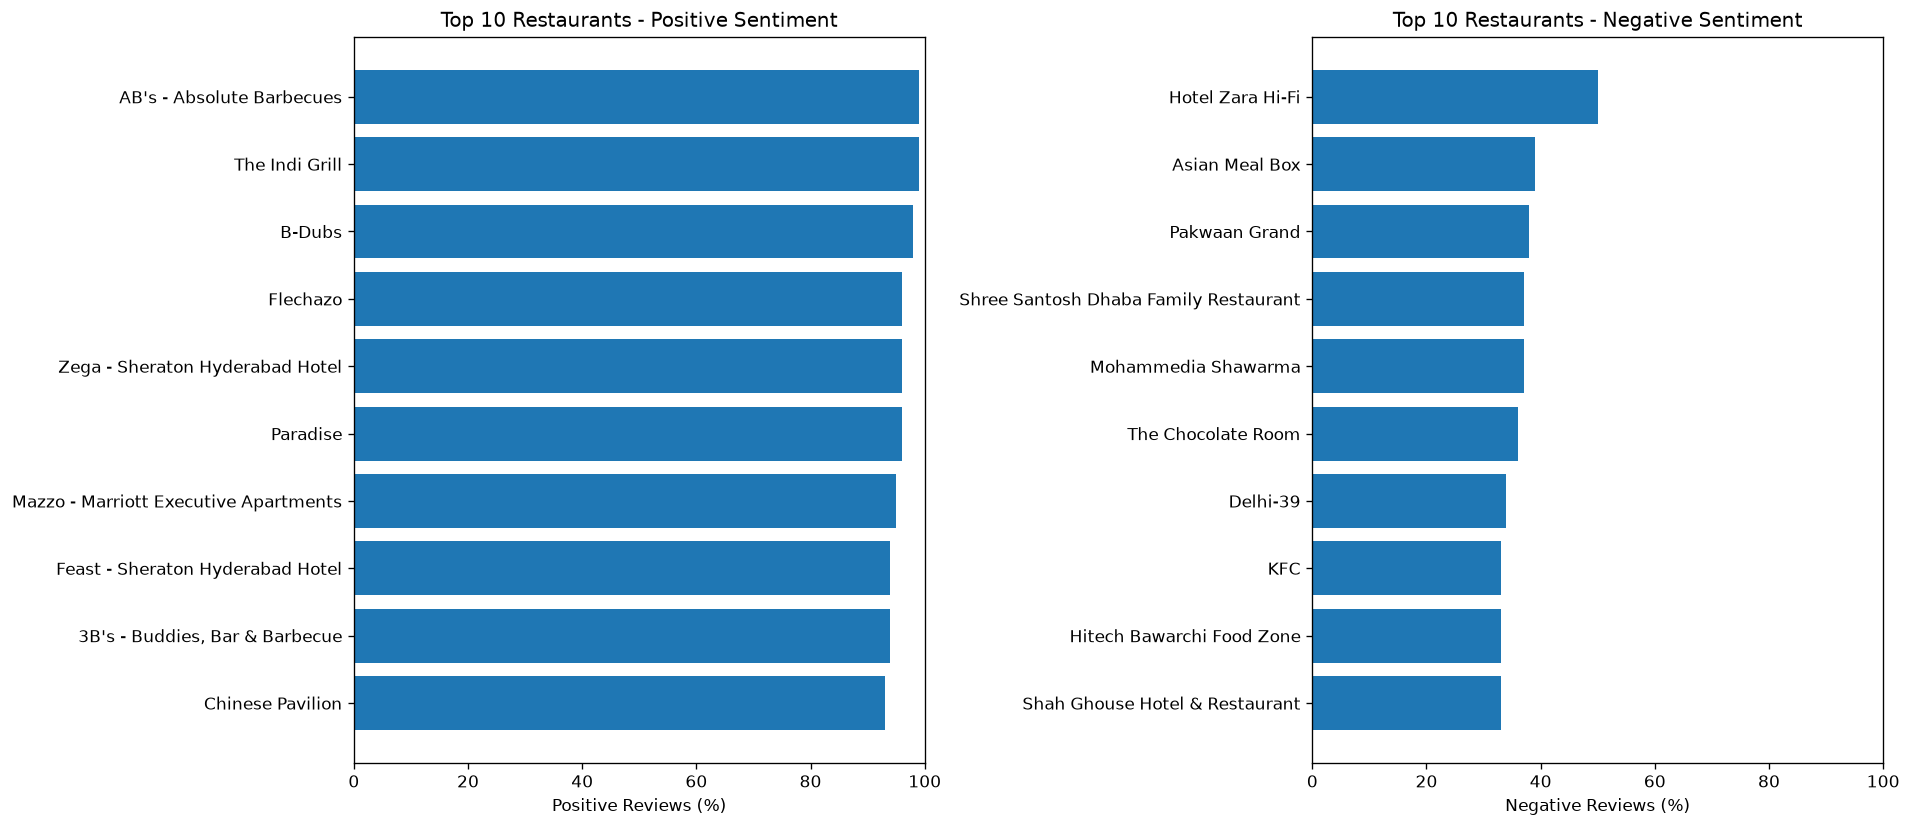

In [38]:
import matplotlib.pyplot as plt

# Create two charts
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Top positive restaurants
top_positive_sorted = top_positive.sort_values(
    'Positive_Percentage'
)

axes[0].barh(
    top_positive_sorted.index,
    top_positive_sorted['Positive_Percentage']
)

axes[0].set_title('Top 10 Restaurants - Positive Sentiment')
axes[0].set_xlabel('Positive Reviews (%)')
axes[0].set_xlim(0, 100)

# Top negative restaurants
top_negative_sorted = top_negative.sort_values(
    'Negative_Percentage'
)

axes[1].barh(
    top_negative_sorted.index,
    top_negative_sorted['Negative_Percentage']
)

axes[1].set_title('Top 10 Restaurants - Negative Sentiment')
axes[1].set_xlabel('Negative Reviews (%)')
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.show()

**Why this chart was chosen**: Two horizontal bar charts were used to compare restaurants with the highest positive-review percentages and the highest negative-review percentages.

**Insight**: AB's - Absolute Barbecues and The Indi Grill are among the restaurants with very high positive sentiment. Hotel Zara Hi-Fi has the highest negative-review percentage among the displayed restaurants, followed by Asian Meal Box and Pakwaan Grand.

**Business impact**: Restaurants with positive sentiment can be studied for successful customer-experience practices. Restaurants with higher negative sentiment can investigate customer complaints and improve service quality.

In [39]:
rating_sentiment = pd.crosstab(
    reviews_clean['Rating'],
    reviews_clean['Sentiment']
)

display(rating_sentiment)

Sentiment,Negative,Neutral,Positive
Rating,,,
1.0,1189,210,336
1.5,5,0,4
2.0,356,85,243
2.5,6,1,12
3.0,213,128,851
3.5,3,0,44
4.0,46,95,2232
4.5,0,0,69
5.0,28,198,3600


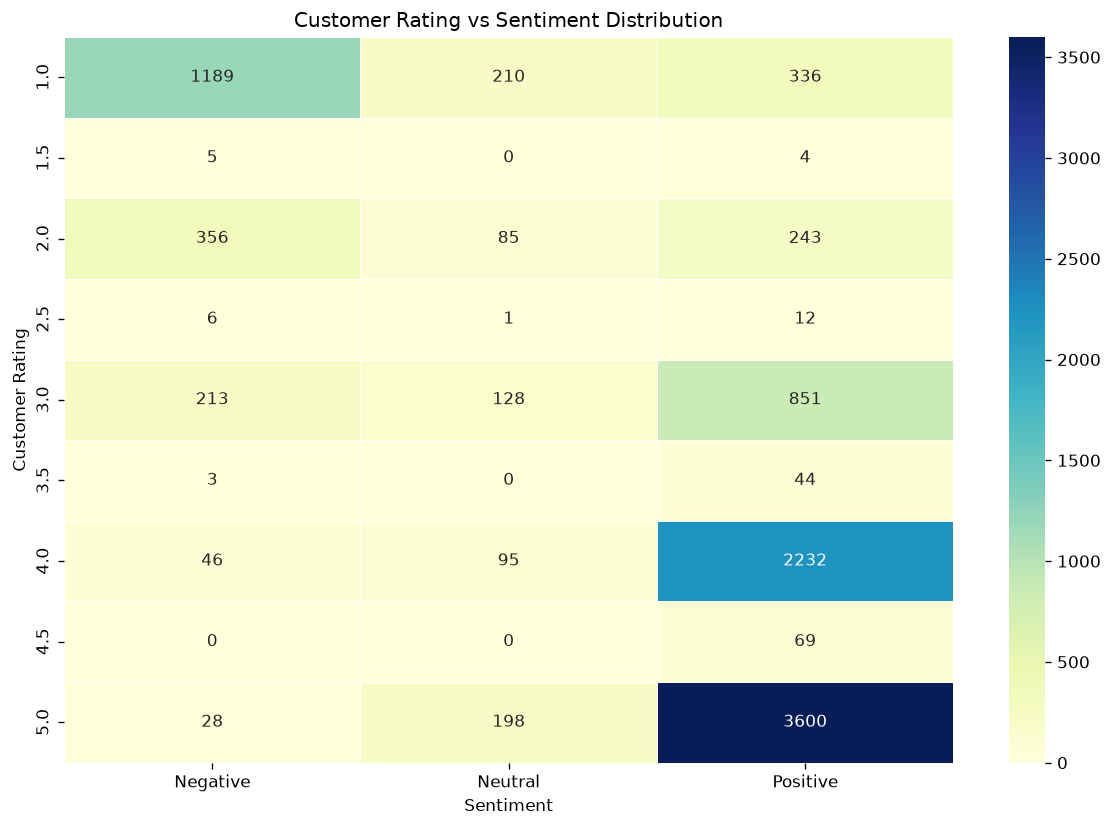

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Create rating and sentiment table
rating_sentiment = pd.crosstab(
    reviews_clean['Rating'],
    reviews_clean['Sentiment']
)

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    rating_sentiment,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Customer Rating vs Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Customer Rating')

plt.tight_layout()
plt.show()

**Why this chart was chosen**: A heatmap was selected to show the relationship between numerical customer ratings and text-based sentiment categories.

**Insights**: Higher ratings are strongly associated with positive sentiment. For example, rating 5.0 has 3,600 positive reviews, while rating 1.0 has 1,189 negative reviews. This indicates a clear relationship between customer ratings and review sentiment.

**Business impact**: Combining numerical ratings with written feedback provides a better understanding of customer satisfaction.

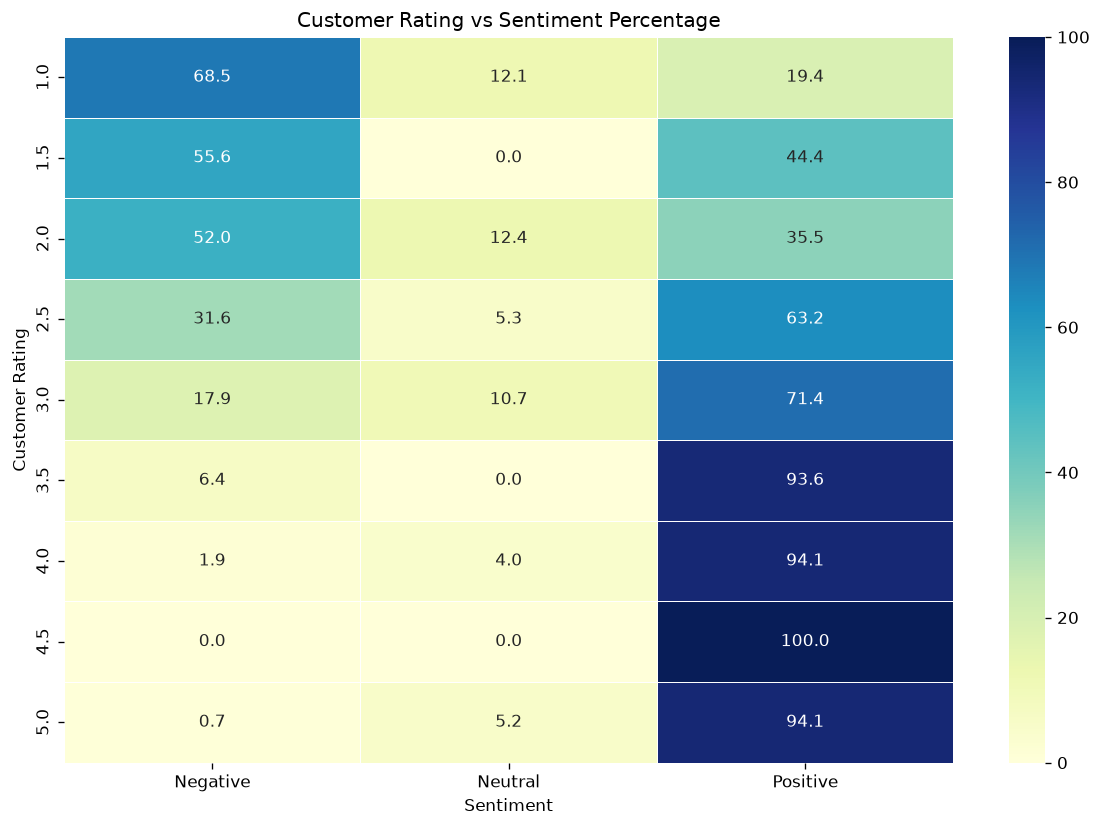

In [41]:
# Convert counts into percentages within each rating
rating_percentage = rating_sentiment.div(
    rating_sentiment.sum(axis=1),
    axis=0
) * 100

plt.figure(figsize=(10, 7))

sns.heatmap(
    rating_percentage,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Customer Rating vs Sentiment Percentage')
plt.xlabel('Sentiment')
plt.ylabel('Customer Rating')

plt.tight_layout()
plt.show()


**Why this chart was chosen**: A percentage heatmap was used to compare sentiment proportions within each customer-rating group.

**Insights**: For ratings of 4.0, 94.1% of reviews are positive. For ratings of 5.0, 94.1% are positive. In comparison, 68.5% of rating-1.0 reviews are negative.

**Business impact**: Percentage comparisons help restaurants understand the sentiment pattern within each rating group rather than relying only on the number of reviews.

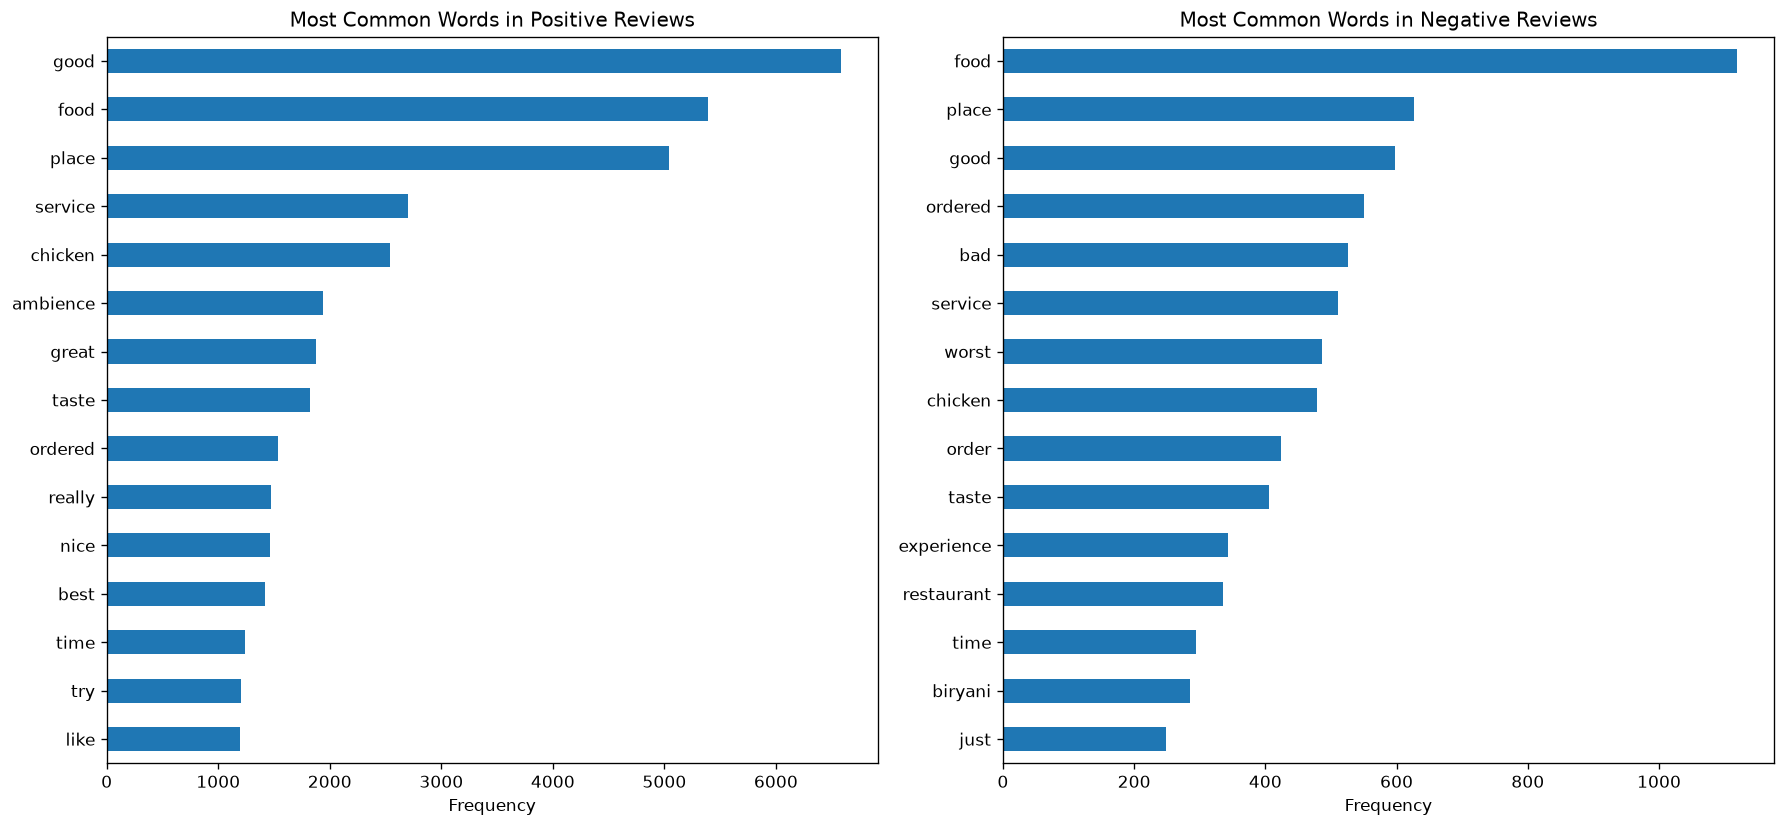

In [42]:
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt

# Separate positive and negative reviews
positive_reviews = reviews_clean[
    reviews_clean['Sentiment'] == 'Positive'
]['Review'].dropna()

negative_reviews = reviews_clean[
    reviews_clean['Sentiment'] == 'Negative'
]['Review'].dropna()

# Function to find frequently used words
def get_common_words(reviews):
    vectorizer = CountVectorizer(
        stop_words='english',
        max_features=15,
        token_pattern=r'(?u)\b[a-zA-Z]{3,}\b'
    )

    word_matrix = vectorizer.fit_transform(reviews)

    word_counts = word_matrix.sum(axis=0).A1

    words = vectorizer.get_feature_names_out()

    return pd.Series(word_counts, index=words).sort_values()

# Calculate common words
positive_words = get_common_words(positive_reviews)
negative_words = get_common_words(negative_reviews)

# Plot positive and negative words
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

positive_words.plot(kind='barh', ax=axes[0])
axes[0].set_title('Most Common Words in Positive Reviews')
axes[0].set_xlabel('Frequency')

negative_words.plot(kind='barh', ax=axes[1])
axes[1].set_title('Most Common Words in Negative Reviews')
axes[1].set_xlabel('Frequency')

plt.tight_layout()
plt.show()

**Why this chart was chosen**: Two horizontal bar charts were used to identify frequently occurring words in positive and negative customer reviews.

**Insights**: Positive reviews frequently contain words such as "good", "food", "place", and "service". Negative reviews also contain words such as "bad", "worst", "experience", and "service". Some words appear in both groups, so they must be interpreted in context.

**Business impact**: Frequent words help restaurants identify what customers commonly discuss and which aspects of the dining experience deserve attention.

In [43]:
from sklearn.feature_extraction.text import CountVectorizer

negative_reviews = reviews_clean[
    reviews_clean['Sentiment'] == 'Negative'
]['Review'].dropna()

vectorizer = CountVectorizer(
    stop_words='english',
    ngram_range=(2, 2),
    max_features=15
)

X = vectorizer.fit_transform(negative_reviews)

phrase_counts = X.sum(axis=0).A1
phrases = vectorizer.get_feature_names_out()

top_phrases = pd.Series(
    phrase_counts,
    index=phrases
).sort_values(ascending=False)

display(top_phrases.to_frame('Frequency'))

,Frequency
worst experience,83
bad experience,81
main course,64
waste money,64
food good,62
ordered chicken,57
ice cream,56
taste good,56
quality food,49
non veg,45


In [44]:
# Search negative reviews containing complaint-related phrases

complaint_phrases = [
    'worst experience',
    'bad experience',
    'waste money',
    'worst food',
    'worst service',
    'food quality'
]

for phrase in complaint_phrases:
    print("\nCOMPLAINT:", phrase.upper())

    matching_reviews = reviews_clean[
        (reviews_clean['Sentiment'] == 'Negative') &
        (reviews_clean['Review'].str.contains(
            phrase, case=False, na=False
        ))
    ]

    display(matching_reviews[['Restaurant', 'Review']].head(3))


COMPLAINT: WORST EXPERIENCE

COMPLAINT: BAD EXPERIENCE

COMPLAINT: WASTE MONEY

COMPLAINT: WORST FOOD

COMPLAINT: WORST SERVICE

COMPLAINT: FOOD QUALITY


,Restaurant,Review
123,Paradise,i have ordered 2 special chicken biryani's and received two ordinary biryani's with bones! this is a big time disappointment. this place was known for its biryani and now i feel like i have had a worst biryani.\n\nit costed 400 bucks each and receiving the same 200 bucks biryani has been my worst experience.
368,Shah Ghouse Hotel & Restaurant,"worst food received, low quality rice was used, egg fried rice was almost spoiler, unable to eat. worst experience ever, does not recommend."
388,Shah Ghouse Hotel & Restaurant,"i had heard a lot about this place so i went there. the dining area was pretty jammed and there seemed a lot of dirt lying around like used napkins, food etc. i anyway passed it for the fact that the place is all time busy. but then i saw a rat nibbling on the scattered food. i reported this to the manager and he told me it's okay and 'ek do galti toh ho jati hai' and they literally forced me to pay for my order which i did not even touch. the staff was highly rude and it has been one of the worst experiences in hyderabad."


,Restaurant,Review
29,Beyond Flavours,food is descent enough. desert options were also good\nstarrers were also tasty.\none bad experience ee had is waiting time even though we booked table prior time.
89,Beyond Flavours,had a very bad experience here\nbeyond flavours really puts you beyond all the flavours\nhad gone here for dinner and the next day had to get hospitalised because of food infection\ni guess the food was not served fresh
93,Beyond Flavours,waiters are not good enough and you will get items which you have not ordered. overall a bad experience. waiting time is more than expected...


,Restaurant,Review
4531,Owm Nom Nom,"worest management.\nthey don't even know the features in delivery.\nthey are refusing to give my own order to myself.\neven after waiting for hours management doesn't respond\nif you want to waste money and time,\nplease visit to this restaurant.\nthis is not the first time we are facining this problem.\nseveral times it happened.\nthey don't even respond to phone calls on customer care number."
8701,American Wild Wings,"out of hunger and trust on the restaurant i ordered a chicken burger from american wild wings, gachibowli hoping it would be tasty and healthy but the kind of service i recieved was really pathetic. at first the restaurant took almost 40 mins to prepare just a small chicken burger, i tried calling restaurant about the update and they weren't even responsive, didn't answer any of my call. i kept my patience and waited for the order to arrive. aftr receiving the order what i saw was really a bad experience. the french fries that i used to get always were replaced by some oily, smelly, rotten potato pakodis. not just that i hoped my burger to be nice but it was again a big disappointment. the very first bite of it tasted really bad. chicken seemed fried to be in very bad oil and smelled filthy. i had to throw it after my first three bites. and then after sometime i even started having pain in my stomach . this particular experience of mine was very disappointing with american wild wings. i didn't think of myself to waste money, wait for an hour and still get suffer after eating that food"


,Restaurant,Review
345,Shah Ghouse Hotel & Restaurant,"worst food, no quality this would be the worst biryani i ever i had in my entire life. this the chicken biryani without chicken and the chicken is mashed up and keema and i would say this is chicken keema biryani 🤣🤣🤣."
368,Shah Ghouse Hotel & Restaurant,"worst food received, low quality rice was used, egg fried rice was almost spoiler, unable to eat. worst experience ever, does not recommend."
630,eat.fit,worst food ..... i would never order from this again... i ordered lucknowi biryani .... that turned out bullshittt.... it looked like timato chutney rice ....


,Restaurant,Review
92,Beyond Flavours,it’s a worst service experience. food was ok. they took 45mins to get veg pulav. never seen a restaurant to take such time. won’t visit again.
1306,The Lal Street - Bar Exchange,worst service experienced ever.\nnobody is concerned about even taking the order.\nits just waste of our evening.\nnot as expected.\nthis review is completely for the service we received.
1367,The Lal Street - Bar Exchange,one of the worst service ever i recieved today. i don't wana refer anyone to this place. i contacted the lal street they told me about the happy hours menu and after going there tha menu has been totally changed i. e. from 1+1 to 99 and i didnt like this and worst ever service


,Restaurant,Review
83,Beyond Flavours,food quality and taste is not good. super slow service. nice ambience but very poor in customer handling. lot of items not available even if in the menu.
366,Shah Ghouse Hotel & Restaurant,i ordered chicken biryani online.. zomato delivered it ontime but food quality was very bad.. honestly i doubt whether they are serving chicken or some other meat.. i had to thrown the biryani that they delivered.. very bad restaurant that i felt.
641,eat.fit,"food quality and quantity is not up to mark. a family pack of chicken biriyani comes with 430 rs and it contains only 2 pretty small pieces and rice relatively very less. no raita or salan given. not at all worth for money.\nquality is also not very good, didn't feel anything great about , worst place to order food. sorry however that's the reality.. thanks."


In [45]:
import re

negative_reviews = reviews_clean[
    reviews_clean['Sentiment'] == 'Negative'
].copy()

complaint_categories = {
    'Food Quality': r'food quality|worst food|bad food|taste|stale',
    'Service': r'worst service|bad service|slow service|poor service',
    'Delivery': r'delivery|late delivery|delayed|cold food',
    'Price and Value': r'waste money|overpriced|expensive|price',
    'Food Quantity': r'quantity|less quantity|small portion'
}

category_counts = {}

for category, keywords in complaint_categories.items():
    matches = negative_reviews['Review'].str.contains(
        keywords, case=False, na=False, regex=True
    )
    category_counts[category] = matches.sum()

complaint_summary = pd.DataFrame(
    list(category_counts.items()),
    columns=['Complaint Category', 'Review Count']
).sort_values('Review Count', ascending=False)

display(complaint_summary)

,Complaint Category,Review Count
0,Food Quality,536
3,Price and Value,135
2,Delivery,104
1,Service,102
4,Food Quantity,98


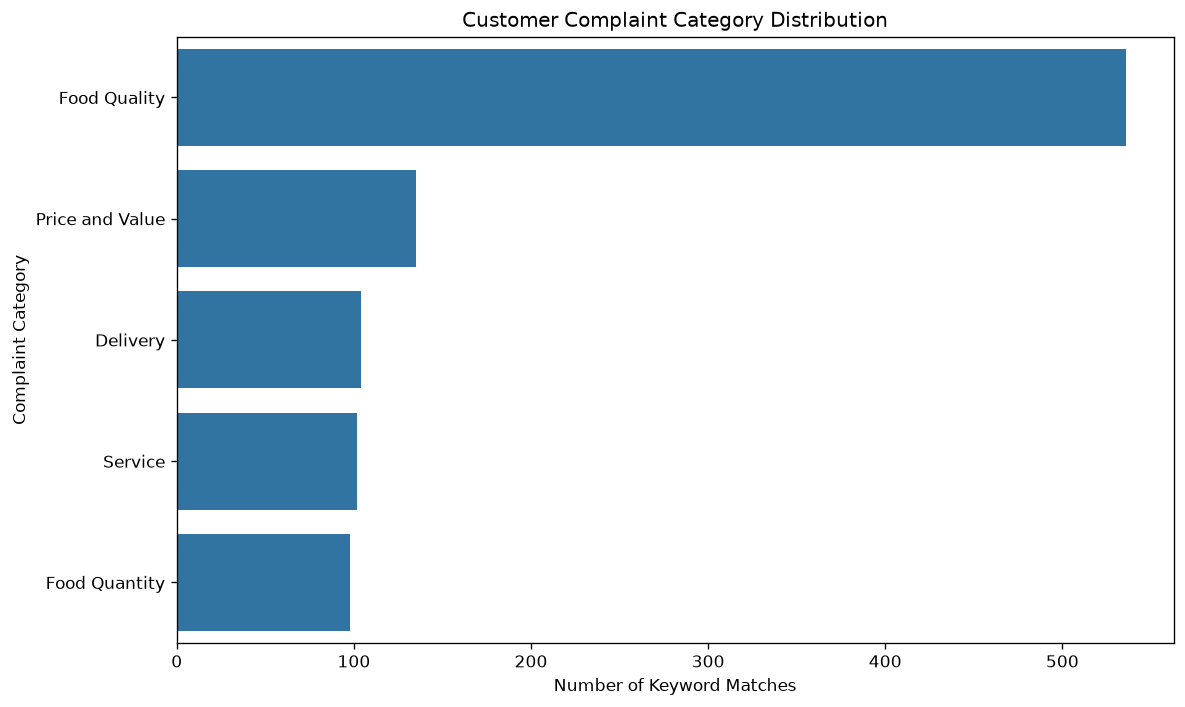

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=complaint_summary,
    x='Review Count',
    y='Complaint Category'
)

plt.title('Customer Complaint Category Distribution')
plt.xlabel('Number of Keyword Matches')
plt.ylabel('Complaint Category')

plt.tight_layout()
plt.show()

**Why this chart was chosen**: A horizontal bar chart was used to compare the frequency of keyword matches across different complaint categories.

**Insights**: Food Quality has the highest number of keyword matches at 536, followed by Price and Value at 135, Delivery at 104, Service at 102, and Food Quantity at 98.

**Business impact**: Food quality appears to be the most prominent complaint area in this keyword-based analysis. Restaurants can prioritise food consistency and quality improvements.

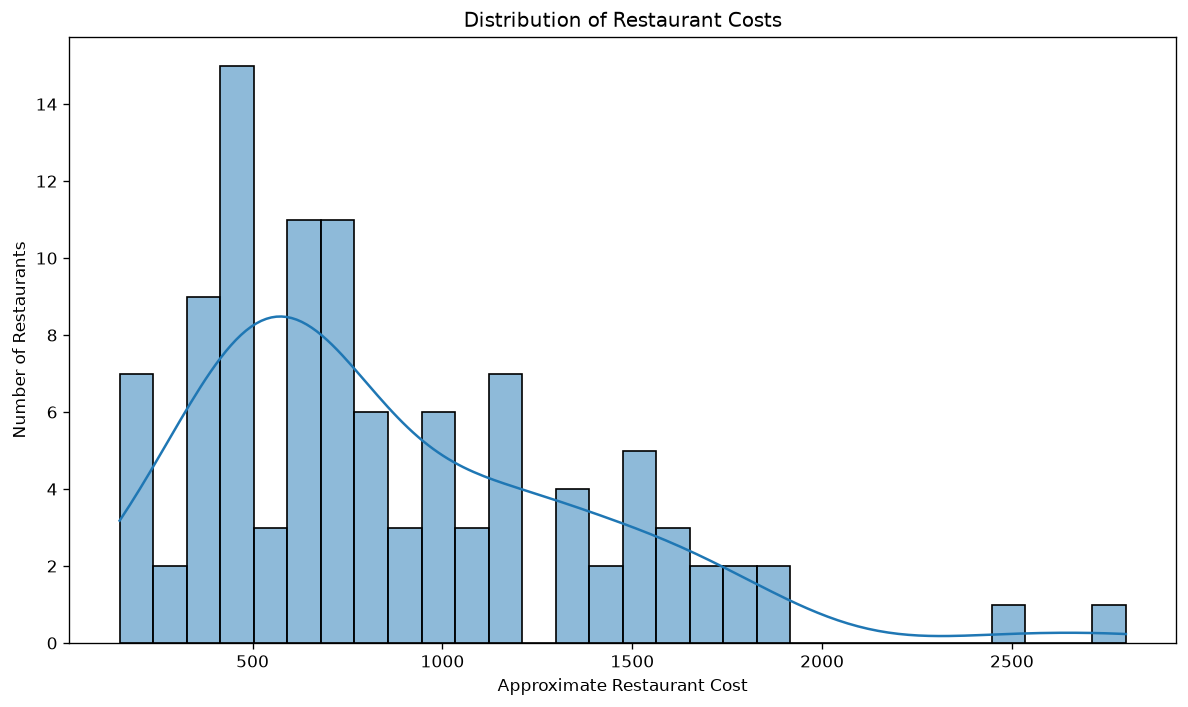

In [47]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=restaurants_clean,
    x='Cost',
    bins=30,
    kde=True
)

plt.title('Distribution of Restaurant Costs')
plt.xlabel('Approximate Restaurant Cost')
plt.ylabel('Number of Restaurants')

plt.tight_layout()
plt.show()

**Additional Cost Distribution View** : This histogram uses more bins to provide a more detailed view of restaurant pricing. It confirms that most restaurants fall within the lower-to-middle cost ranges, while fewer restaurants belong to the high-cost range. This additional view helps examine the price distribution in greater detail.

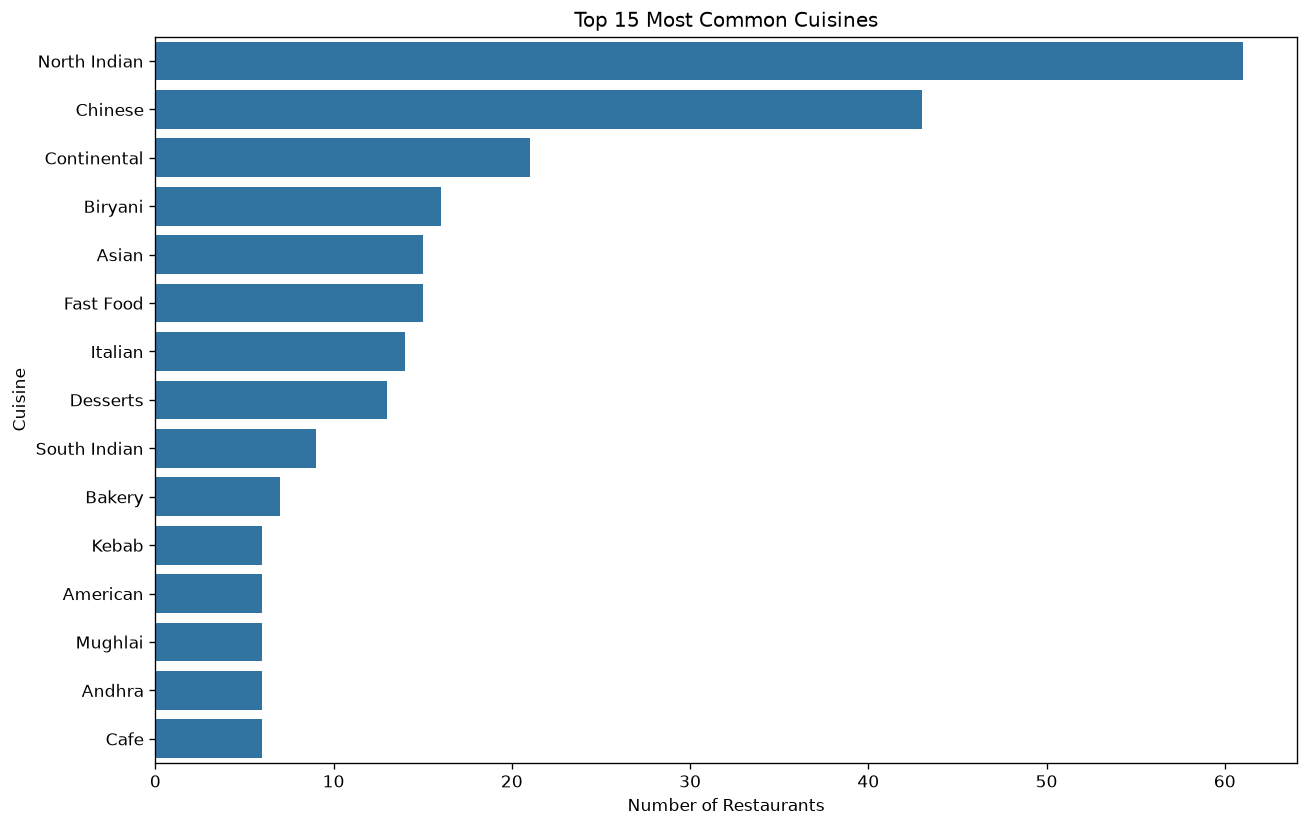

In [48]:
# Split cuisines and count individual cuisine types
cuisine_data = (
    restaurants_clean['Cuisines']
    .dropna()
    .str.split(',')
    .explode()
    .str.strip()
)

top_cuisines = cuisine_data.value_counts().head(15)

# Plot
plt.figure(figsize=(11, 7))

sns.barplot(
    x=top_cuisines.values,
    y=top_cuisines.index
)

plt.title('Top 15 Most Common Cuisines')
plt.xlabel('Number of Restaurants')
plt.ylabel('Cuisine')

plt.tight_layout()
plt.show()

**Why this chart was chosen**: A horizontal bar chart was used to expand the cuisine comparison from the top 10 to the top 15 categories.

**Insights**: North Indian and Chinese cuisines remain the most common categories, followed by Continental and Biryani. Other categories include Asian, Fast Food, Italian, Desserts, South Indian, Bakery, Mughlai, Kebab, Andhra, Cafe, and American.

**Business impact**: A wider cuisine comparison provides more information about restaurant variety and helps identify additional market opportunities.

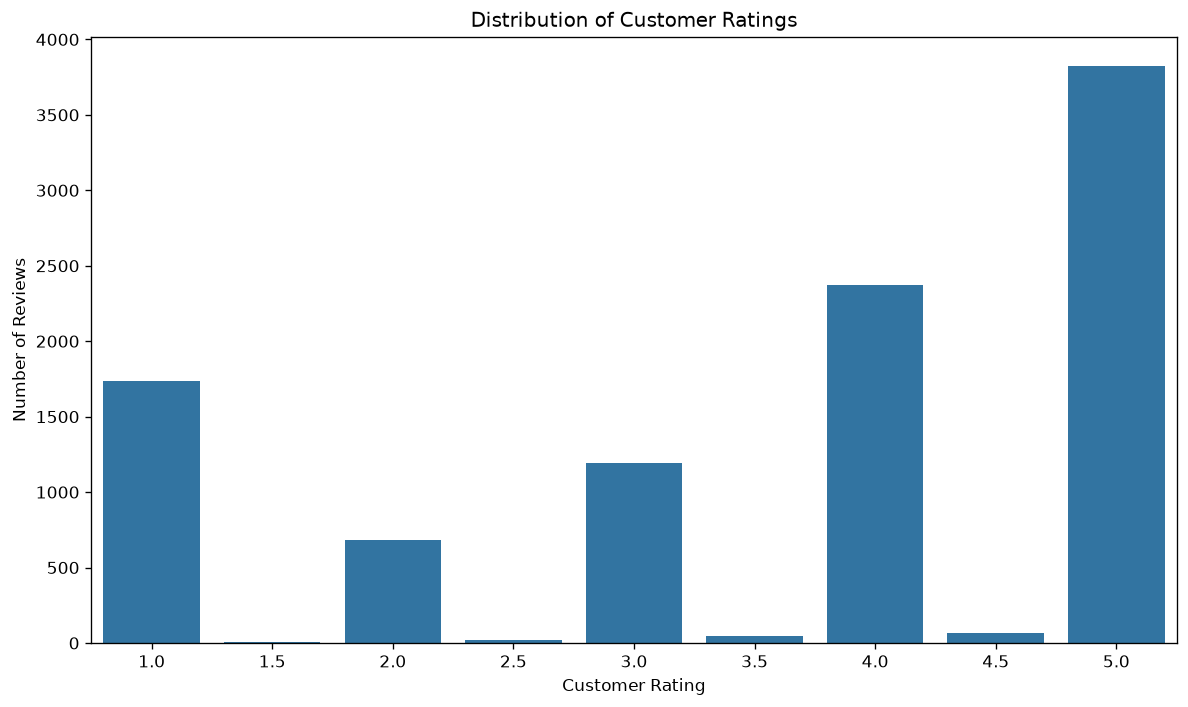

In [49]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=reviews_clean,
    x='Rating',
    order=sorted(reviews_clean['Rating'].dropna().unique())
)

plt.title('Distribution of Customer Ratings')
plt.xlabel('Customer Rating')
plt.ylabel('Number of Reviews')

plt.tight_layout()
plt.show()

**Why this chart was chosen**: A count plot was used to display the frequency of each customer-rating value.

**Insights**: Ratings of 5.0 and 4.0 occur most frequently, while ratings of 1.0 also form a noticeable group. Half-star ratings are much less frequent.

**Business impact**: This helps businesses monitor customer satisfaction and understand the distribution of feedback.

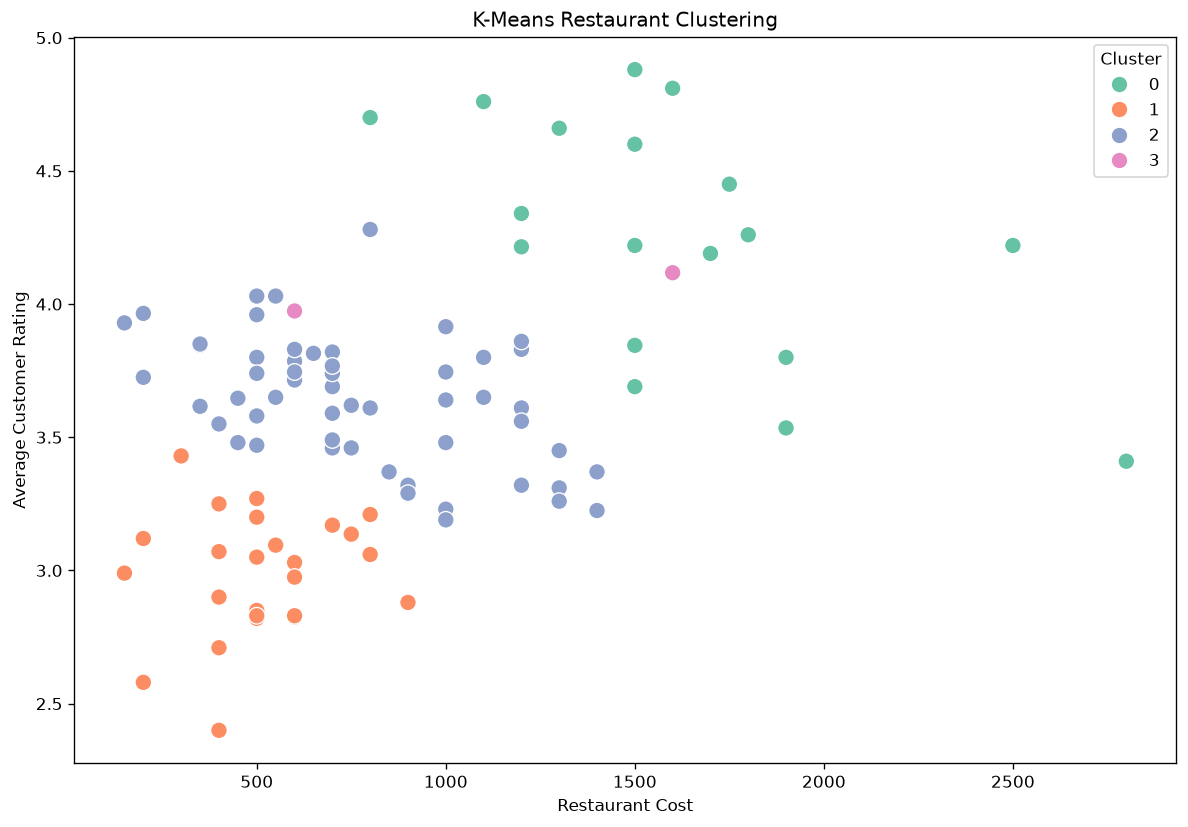

In [50]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=cluster_data,
    x='Cost',
    y='Average_Rating',
    hue='Cluster',
    palette='Set2',
    s=100
)

plt.title('K-Means Restaurant Clustering')
plt.xlabel('Restaurant Cost')
plt.ylabel('Average Customer Rating')
plt.legend(title='Cluster')

plt.tight_layout()
plt.show()

**Why this chart was chosen**: A second scatter plot was used to display the K-Means restaurant clusters in another section of the notebook.

**Insights**: The chart shows restaurant groups with different cost and average-rating combinations. It provides another view of the separation between lower-cost, moderate-rating restaurants and higher-cost, higher-rating restaurants.

**Business impact**: This visualisation supports the use of restaurant segments for competitor comparison and pricing strategies.

**Hypothesis 3: Relationship Between Customer Rating and Review Sentiment**

**Null Hypothesis (H₀):** Customer ratings and text-based review sentiment are independent of each other.

**Alternative Hypothesis (H₁):** Customer ratings and text-based review sentiment are associated with each other.

**Test selected:** Chi-Square Test of Independence.

**Reason for selection:** This test is suitable for examining whether two categorical variables are significantly associated.

**Result:** Chi-square statistic = 5134.8071, degrees of freedom = 16, p-value < 0.001.

**Conclusion:** Since the p-value is below 0.05, the null hypothesis is rejected. There is a statistically significant association between customer ratings and text-based review sentiment. However, this does not establish causation.

## 7. Hypothesis Testing

These tests examine associations and group differences in the observed data. Statistical significance does not imply causation.


**Hypothesis Testing**

Hypothesis testing is used to determine whether relationships and differences observed in the restaurant dataset are statistically significant. Three statistical tests were performed to investigate restaurant pricing, customer ratings, and review sentiment.

### Hypothesis 1: Restaurant Cost and Average Rating

**Null Hypothesis (H₀):** There is no statistically significant difference in average restaurant ratings across different restaurant cost groups.

**Alternative Hypothesis (H₁):** At least one restaurant cost group has a significantly different average rating.

**Test selected:** Kruskal-Wallis H-test.

**Reason for selection:** This non-parametric test compares three or more independent groups and does not require the data to follow a normal distribution.

**Result:** H-statistic = 19.9015, p-value = 0.0000477 in the verified rerun.

**Conclusion:** Since the p-value is below 0.05, the null hypothesis is rejected. There is a statistically significant difference in ratings across the restaurant cost groups.

In [51]:
import pandas as pd
from scipy.stats import kruskal

# Prepare clean data
test_data = cluster_data[['Cost', 'Average_Rating']].dropna().copy()

# Divide restaurants into three price groups
test_data['Price_Group'] = pd.qcut(
    test_data['Cost'].rank(method='first'),
    q=3,
    labels=['Low Cost', 'Medium Cost', 'High Cost']
)

# Display group sizes and median ratings
print("PRICE GROUP SUMMARY")
display(
    test_data.groupby('Price_Group', observed=True)['Average_Rating']
    .agg(['count', 'median', 'mean'])
)

# Perform Kruskal-Wallis test
groups = [
    test_data.loc[
        test_data['Price_Group'] == group,
        'Average_Rating'
    ]
    for group in ['Low Cost', 'Medium Cost', 'High Cost']
]

statistic, p_value = kruskal(*groups)

print("\nKRUSKAL-WALLIS TEST: COST VS RATING")
print("Test statistic:", round(statistic, 4))
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: There is a statistically significant difference.")
else:
    print("Conclusion: No statistically significant difference was found.")

PRICE GROUP SUMMARY

KRUSKAL-WALLIS TEST: COST VS RATING
Test statistic: 19.9015
P-value: 4.769096325866948e-05
Conclusion: There is a statistically significant difference.


,count,median,mean
Price_Group,,,
Low Cost,34,3.450,3.360518
Medium Cost,33,3.490,3.512236
High Cost,33,3.845,3.940232


**Hypothesis 2: Relationship Between Restaurant Cost and Average Rating**

**Null Hypothesis (H₀):** There is no monotonic relationship between restaurant cost and average customer rating.

**Alternative Hypothesis (H₁):** There is a monotonic relationship between restaurant cost and average customer rating.

**Test selected:** Spearman's rank correlation.

**Reason for selection:** Spearman's correlation measures the strength and direction of a monotonic relationship and does not require the variables to be normally distributed.

**Result:** Spearman correlation = 0.3844, p-value = 0.0000787 in the verified rerun.

**Conclusion:** Since p < 0.05, reject the null hypothesis. There is a statistically significant positive monotonic association between restaurant cost and average rating. This indicates that higher-cost restaurants tend to have higher ratings in this dataset, but it does not establish causation.

In [52]:
from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    cluster_data['Cost'],
    cluster_data['Average_Rating']
)

print("Spearman correlation:", round(correlation, 4))
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Significant relationship between cost and rating.")
else:
    print("Conclusion: No significant relationship between cost and rating.")

Spearman correlation: 0.3844
P-value: 7.871651426255211e-05
Conclusion: Significant relationship between cost and rating.


In [53]:
from scipy.stats import chi2_contingency

# Create contingency table
rating_sentiment = pd.crosstab(
    reviews_clean['Rating'],
    reviews_clean['Sentiment']
)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    rating_sentiment
)

print("CHI-SQUARE TEST: RATING VS SENTIMENT")
print("-------------------------------------")
print("Chi-square statistic:", round(chi2, 4))
print("P-value:", p_value)
print("Degrees of freedom:", dof)

if p_value < 0.05:
    print("Conclusion: There is a statistically significant association.")
else:
    print("Conclusion: No statistically significant association.")

CHI-SQUARE TEST: RATING VS SENTIMENT
-------------------------------------
Chi-square statistic: 5134.8071
P-value: 0.0
Degrees of freedom: 16
Conclusion: There is a statistically significant association.


## Hyperparameter Search and Final Model Selection

Candidate K values from 2 through 8 are evaluated on the same scaled features using silhouette score and inertia. The selected value is computed from the results table below, so the notebook does not rely on a hard-coded score or claim cross-validation.


In [54]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Scale the features
scaler = StandardScaler()
# Use only the original input features; exclude any earlier cluster labels.
scaled_features = scaler.fit_transform(cluster_data[features])

# Test different numbers of clusters
results = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_features)

    score = silhouette_score(scaled_features, labels)

    results.append({
        'Number of Clusters': k,
        'Silhouette Score': round(score, 4),
        'Inertia': round(model.inertia_, 2)
    })

tuning_results = pd.DataFrame(results)
print(tuning_results)

best_k = tuning_results.loc[
    tuning_results['Silhouette Score'].idxmax(),
    'Number of Clusters'
]

print("\nBest number of clusters:", best_k)

   Number of Clusters  Silhouette Score  Inertia
0                   2            0.4655   201.38
1                   3            0.4673   110.37
2                   4            0.3797    78.98
3                   5            0.4261    57.64
4                   6            0.4510    43.20
5                   7            0.4416    36.88
6                   8            0.4241    32.33

Best number of clusters: 3


In [55]:
from sklearn.cluster import KMeans

kmeans_final = KMeans(
    n_clusters=int(best_k),
    random_state=42,
    n_init=10
)

cluster_data['Cluster'] = kmeans_final.fit_predict(scaled_features)

print("Final K-Means Silhouette Score:",
      round(silhouette_score(scaled_features, cluster_data['Cluster']), 4))

print("\nCluster Sizes:")
print(cluster_data['Cluster'].value_counts().sort_index())

print("\nCluster Profiles:")
print(cluster_data.groupby('Cluster').mean().round(2))

Final K-Means Silhouette Score: 0.4673

Cluster Sizes:
Cluster
0    24
1    74
2     2
Name: count, dtype: int64

Cluster Profiles:
            Cost  Average_Rating  Total_Reviews
Cluster                                        
0        1497.92            4.18         100.00
1         662.84            3.40          99.89
2        1100.00            4.05          81.00


In [56]:
# Display the model comparison calculated above using consistent model settings.
print("FINAL CLUSTERING MODEL COMPARISON")
display(comparison.round(4))


FINAL CLUSTERING MODEL COMPARISON


,Model,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score,Evaluation Set
0,K-Means (K=3),0.4673,0.7071,83.3246,All restaurants
1,Agglomerative (K=3),0.4181,0.7897,80.7440,All restaurants
2,DBSCAN (eps=0.3),0.5098,0.6036,82.6095,Non-noise restaurants only (56 of 100)


### Clustering Model Comparison and Interpretation

K-Means and Agglomerative Clustering are compared on all restaurants using three clusters. DBSCAN metrics use non-noise observations only, so they are not directly comparable. The tuned K-Means model is selected for interpretable segments; review the measured scores above before drawing conclusions.


# Final Conclusion

## Project: Zomato Restaurant Clustering and Sentiment Analysis

This project used restaurant metadata and customer reviews to analyse restaurant performance, identify customer preferences, and discover meaningful restaurant groups.

Data cleaning, preprocessing, feature engineering, exploratory data analysis, and sentiment analysis were performed to prepare the data for machine learning.

Three unsupervised clustering algorithms were explored: K-Means, Agglomerative Clustering, and DBSCAN. After evaluating and tuning the models, K-Means with three clusters was selected, with its measured silhouette score reported in the executed results above.

The clusters revealed differences in restaurant cost, average customer ratings, and review counts. Sentiment analysis results are reported in the executed sentiment summary above.

Three statistical tests were used to investigate relationships between restaurant ratings, costs, and customer review sentiment. The results provided evidence of significant relationships in the analysed dataset.

## Business Insights

1. Restaurants can use customer sentiment to understand customer satisfaction and identify areas needing improvement.
2. Restaurant clusters can help businesses understand differences in pricing and customer ratings.
3. Negative review patterns can highlight common complaints related to food quality, pricing, delivery, and service.
4. Businesses can use these insights to improve customer experience and make data-driven decisions.

## Limitations

- The analysis was based on the available dataset and may not represent every Zomato restaurant.
- The clustering dataset contained only 100 merged restaurants.
- The Total_Reviews feature showed very little variation across restaurants.
- DBSCAN classified several observations as noise.
- VADER sentiment analysis may not fully understand sarcasm, mixed-language reviews, or local expressions.
- The cluster containing only two restaurants should be interpreted cautiously.

## Future Scope

Future work could include a larger restaurant dataset, additional features such as location and cuisine, improved multilingual sentiment analysis, and more advanced clustering techniques.

## Overall Conclusion

The project demonstrates how unsupervised machine learning and sentiment analysis can help identify restaurant segments, understand customer opinions, and generate useful business insights from restaurant data.